# Exploratory Data Analysis 
## Looking at data intending to get labelled spiked data to train the model

Hitting the API into a csv (for ease of use)

In [2]:
# from collections import defaultdict

# import requests
# import pandas as pd
# import time

# url = "https://sacaqm.web.cern.ch/dbread.php"

# sensor_ids = [
#     "80F3DA5493DC", "80F3DA54B464", "80F3DA551440", "80F3DA5580BC",
#     "80F3DA54E9F8", "80F3DA5474CC", "351901936252711", "80F3DA550AFC",
#     "80F3DA53CDFC", "80F3DA543464", "80F3DA50BD74", "80F3DA53A570",
#     "80F3DA545DE0", "80F3DA50B704", "80F3DA546CB8", "80F3DA547384",
#     "80F3DA50F2C0", "80F3DA542D5C", "80F3DA50DE3C", "351901936738230",
#     "80F3DA50E388", "80F3DA50EEC8", "80F3DA550F78", "80F3DA547534",
#     "80F3DA55B134", "80F3DA54C238", "80F3DA50F530", "80F3DA559B2C",
#     "80F3DA53FFDC", "80F3DA53E828", "80F3DA539154", "80F3DA5595B8",
#     "80F3DA53D9E8", "80F3DA558250", "80F3DA540038", "80F3DA543A10",
#     "80F3DA544CC0", "80F3DA54AD58", "80F3DA558BC0", "80F3DA5573F8",
#     "80F3DA50DE58", "80F3DA557E14", "80F3DA542CDC", "80F3DA53D73C",
#     "80F3DA542A94", "350976655351689", "80F3DA558DF0", "80F3DA557C08",
#     "351901936738875", "004B122FD0F8", "1C6920945B00", "80F3DA558028",
#     "80F3DA5544D4", "80F3DA558251", "80F3DA549348", "80F3DA55B124",
#     "351901936739550", "80F3DA549B40", "351901935957088", "350976650247924"]

# month_dictionary = {
#     "01": "january",
#     "02": "february",
#     "03": "march",
#     "04": "april",
#     "05": "may",
#     "06": "june",
#     "07": "july",
#     "08": "august",
#     "09": "september",
#     "10": "october",
#     "11": "november",
#     "12": "december"
# }

# all_data = []

# for sensor_id in sensor_ids:
#     params = {
#         "cmd": "get_sen55",
#         "sensor_id": sensor_id,
#         "from": "2026-03-04T08:13:38Z",
#         "to": "2026-07-02T23:59:59Z"
#     }

#     try:
#         response = requests.get(url, params=params)
#         response.raise_for_status()
#         data = response.json()

#         if data:
#             all_data.extend(data)
#             print(f"Data fetched for sensor {sensor_id}")
#         else:
#             print(f"No data found for sensor {sensor_id}")

#     except requests.RequestException as e:
#         print(f"Error fetching data for sensor {sensor_id}: {e}")

#     time.sleep(1)  # Sleep for 1 second to avoid overwhelming the server

# # Create dictionary to store data by month
# monthly_data = defaultdict(list)

# for entry in all_data:
#     timestamp = entry.get("timestamp")
#     if timestamp:
#         month = timestamp[5:7]  # Extract the month (MM)
#         month_name = month_dictionary.get(month)
#         if month_name:
#             monthly_data[month_name].append(entry)

# for month, data in monthly_data.items():
#     df = pd.DataFrame(data)
#     df.to_csv(f"{month}_data.csv", index=False)
#     print(f"Data for {month} saved to {month}_data.csv")

In [3]:
import requests
import pandas as pd
import time

march_df = pd.read_csv("raw_data/march_data.csv")
april_df = pd.read_csv("raw_data/april_data.csv")
may_df = pd.read_csv("raw_data/may_data.csv")
june_df = pd.read_csv("raw_data/june_data.csv")
july_df = pd.read_csv("raw_data/july_data.csv")

df = pd.concat(
    [march_df, april_df, may_df, june_df, july_df],
    ignore_index=True
)


# add field for month
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["month"] = df["timestamp"].dt.to_period("M")
# get all data types in the DataFrame
print(df.dtypes)

id                      int64
sensor_id              object
timestamp      datetime64[ns]
temperature           float64
humidity              float64
pm1p0                 float64
pm2p5                 float64
pm4p0                 float64
pm10p0                float64
voc                   float64
nox                   float64
co2                   float64
latitude              float64
longitude             float64
altitude              float64
area                   object
operator               object
cellid                 object
dba                   float64
month               period[M]
dtype: object


In [4]:
# convert object columns to proper data types
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df['sensor_id'] = df['sensor_id'].astype(str)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['temperature'] = pd.to_numeric(df['temperature'], errors='coerce')
df['humidity'] = pd.to_numeric(df['humidity'], errors='coerce')
df['pm2p5'] = pd.to_numeric(df['pm2p5'], errors='coerce')
df['pm1p0'] = pd.to_numeric(df['pm1p0'], errors='coerce')
df['pm10p0'] = pd.to_numeric(df['pm10p0'], errors='coerce')
df['pm4p0'] = pd.to_numeric(df['pm4p0'], errors='coerce')
df['voc'] = pd.to_numeric(df['voc'], errors='coerce')
df['nox'] = pd.to_numeric(df['nox'], errors='coerce')
df['co2'] = pd.to_numeric(df['co2'], errors='coerce')
df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
df['altitude'] = pd.to_numeric(df['altitude'], errors='coerce')
df['area'] = df['area'].astype(str)
df['operator'] = df['operator'].astype(str)
df['cellid'] = df['cellid'].astype(str)
df['dba'] = pd.to_numeric(df['dba'], errors='coerce')

In [5]:
# Number of unique station IDs
print(df['sensor_id'].nunique())

# print the unique station IDs
print(df['sensor_id'].unique())

60
['80F3DA54B464' '80F3DA551440' '80F3DA5580BC' '80F3DA543464'
 '80F3DA545DE0' '80F3DA50B704' '80F3DA547384' '80F3DA542D5C'
 '351901936738230' '80F3DA50EEC8' '80F3DA550F78' '80F3DA55B134'
 '80F3DA50F530' '80F3DA53E828' '80F3DA539154' '80F3DA5595B8'
 '80F3DA558250' '80F3DA540038' '80F3DA543A10' '80F3DA558BC0'
 '80F3DA50DE58' '80F3DA542A94' '351901936738875' '004B122FD0F8'
 '1C6920945B00' '80F3DA558028' '80F3DA5544D4' '80F3DA558251'
 '351901936739550' '80F3DA549B40' '80F3DA54E9F8' '351901936252711'
 '80F3DA53CDFC' '80F3DA559B2C' '80F3DA53D9E8' '80F3DA5573F8'
 '350976655351689' '80F3DA558DF0' '80F3DA557C08' '80F3DA549348'
 '80F3DA5493DC' '80F3DA550AFC' '80F3DA50BD74' '80F3DA546CB8'
 '80F3DA50F2C0' '80F3DA547534' '80F3DA54C238' '80F3DA53FFDC'
 '80F3DA54AD58' '80F3DA53D73C' '80F3DA5474CC' '80F3DA53A570'
 '80F3DA50DE3C' '80F3DA50E388' '80F3DA544CC0' '80F3DA557E14'
 '80F3DA542CDC' '80F3DA55B124' '351901935957088' '350976650247924']


In [6]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['sensor_id', 'timestamp']) # Sort the DataFrame by sensor_id and timestamp

sensor_summary = df.groupby('sensor_id').agg(
    readings=("pm2p5", "count"),
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max'),
    mean_pm2p5=('pm2p5', 'mean'),
    median_pm2p5=('pm2p5', 'median'),
    max_pm2p5=('pm2p5', 'max'),
    missing_readings=("pm2p5", lambda x: x.isna().sum())
).reset_index()

sensor_summary.sort_values(by='readings', ascending=False, inplace=True)
sensor_summary.head(20)

,sensor_id,readings,start_time,end_time,mean_pm2p5,median_pm2p5,max_pm2p5,missing_readings
56,80F3DA5595B8,34339,2026-03-04 08:17:03,2026-07-02 15:09:06,2.688788,1.6,66.2,0
25,80F3DA542A94,34334,2026-03-04 08:16:06,2026-07-02 15:12:07,5.354890,2.9,110.4,0
22,80F3DA53E828,34332,2026-03-04 08:14:31,2026-07-02 15:06:18,2.511121,1.5,71.7,0
51,80F3DA5580BC,34304,2026-03-04 08:18:12,2026-07-02 15:00:18,5.517205,3.0,707.3,0
28,80F3DA543464,34298,2026-03-04 08:14:44,2026-07-02 15:04:44,5.438477,3.0,162.2,0
45,80F3DA551440,34122,2026-03-04 08:17:42,2026-07-02 15:00:18,3.871195,1.4,6016.0,0
29,80F3DA543A10,33696,2026-03-04 08:18:34,2026-07-02 15:10:18,9.048632,5.9,141.8,0
17,80F3DA539154,33626,2026-03-04 08:16:46,2026-07-02 15:08:08,7.390686,5.5,352.9,0
12,80F3DA50DE58,32835,2026-03-04 16:37:44,2026-07-02 15:11:16,8.390187,5.0,193.0,0
16,80F3DA50F530,31874,2026-03-10 12:00:07,2026-07-02 15:06:00,13.834765,8.0,696.0,0


## If we retrive all the data from our API, the actual time period of all our data runs through is: 2026-03-04 08:13:38 to current day

In [7]:
import pandas as pd

# --------------------------------------------------
# 1. Clean data types
# --------------------------------------------------

df = df.copy()

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["pm2p5"] = pd.to_numeric(df["pm2p5"], errors="coerce")

# Remove rows with invalid timestamps
df_valid_time = df.dropna(subset=["timestamp"]).copy()

# Align timestamps to 5-minute intervals
df_valid_time["timestamp_5min"] = df_valid_time["timestamp"].dt.floor("5min")


# --------------------------------------------------
# 2. Missing PM2.5 values inside existing rows
# --------------------------------------------------

missing_summary = (
    df.groupby("sensor_id")["pm2p5"]
    .agg(
        total_rows="size",
        missing_pm2p5=lambda x: x.isna().sum(),
        missing_percent=lambda x: x.isna().mean() * 100
    )
    .sort_values("missing_percent", ascending=False)
)

print("Missing PM2.5 values in existing rows:")
display(missing_summary.head(20))


# --------------------------------------------------
# 3. Missing 5-minute timestamp readings per sensor
# --------------------------------------------------

missing_time_summary = []

for sensor_id, group in df_valid_time.groupby("sensor_id"):

    full_range = pd.date_range(
        start=group["timestamp_5min"].min(),
        end=group["timestamp_5min"].max(),
        freq="5min"
    )

    actual_times = group["timestamp_5min"].drop_duplicates()

    missing_times = full_range.difference(actual_times)

    missing_time_summary.append({
        "sensor_id": sensor_id,
        "first_timestamp": group["timestamp_5min"].min(),
        "last_timestamp": group["timestamp_5min"].max(),
        "expected_readings": len(full_range),
        "actual_readings": actual_times.nunique(),
        "missing_timestamps": len(missing_times),
        "missing_timestamp_percent": len(missing_times) / len(full_range) * 100
    })

missing_time_summary = (
    pd.DataFrame(missing_time_summary)
    .sort_values("missing_timestamp_percent", ascending=False)
)

print("Missing 5-minute timestamp readings:")
display(missing_time_summary.head(20))


# raw timestamp gaps
raw_gap_summary = []
for sensor_id, group in df_valid_time.groupby("sensor_id"):
    group = group.sort_values("timestamp").drop_duplicates("timestamp")

    gaps = group["timestamp"].diff().dropna() # Calculate gaps between consecutive timestamps

    raw_gap_summary.append({
        "sensor_id": sensor_id,
        "first_timestamp": group["timestamp"].min(),
        "last_timestamp": group["timestamp"].max(),
        "total_gaps": len(gaps),
        "max_gap": gaps.max(),
        "mean_gap": gaps.mean(),
        "median_gap": gaps.median()
    })

raw_gap_summary = (
    pd.DataFrame(raw_gap_summary)
    .sort_values("max_gap", ascending=False)
)

print("Raw timestamp gaps:")
display(raw_gap_summary.head(20))

Missing PM2.5 values in existing rows:


,total_rows,missing_pm2p5,missing_percent
sensor_id,,,
004B122FD0F8,1964,0,0.0
1C6920945B00,1964,0,0.0
350976650247924,2,0,0.0
350976655351689,5770,0,0.0
351901935957088,1,0,0.0
351901936252711,2888,0,0.0
351901936738230,18581,0,0.0
351901936738875,5798,0,0.0
351901936739550,7150,0,0.0


Missing 5-minute timestamp readings:


,sensor_id,first_timestamp,last_timestamp,expected_readings,actual_readings,missing_timestamps,missing_timestamp_percent
2,350976650247924,2026-06-21 23:00:00,2026-06-22 13:05:00,170,2,168,98.823529
46,80F3DA5544D4,2026-03-04 08:50:00,2026-06-23 10:45:00,31992,1963,30029,93.864091
1,1C6920945B00,2026-03-04 08:50:00,2026-06-23 10:45:00,31992,1964,30028,93.860965
0,004B122FD0F8,2026-03-04 08:50:00,2026-06-23 10:45:00,31992,1964,30028,93.860965
53,80F3DA558251,2026-03-04 08:50:00,2026-06-23 10:45:00,31992,1964,30028,93.860965
50,80F3DA558028,2026-03-04 08:15:00,2026-06-23 10:45:00,31999,3360,28639,89.499672
5,351901936252711,2026-04-23 12:55:00,2026-07-02 12:15:00,20153,2888,17265,85.669627
7,351901936738875,2026-03-23 15:00:00,2026-07-02 09:30:00,29023,5798,23225,80.022741
8,351901936739550,2026-03-04 08:10:00,2026-07-01 14:50:00,34353,7150,27203,79.186679
3,350976655351689,2026-04-23 13:20:00,2026-07-02 15:05:00,20182,5767,14415,71.425032


Raw timestamp gaps:


,sensor_id,first_timestamp,last_timestamp,total_gaps,max_gap,mean_gap,median_gap
3,350976655351689,2026-04-23 13:22:01,2026-07-02 15:09:56,5769,32 days 03:32:55,0 days 00:17:29.484312705,0 days 00:05:36
8,351901936739550,2026-03-04 08:14:05,2026-07-01 14:54:16,7149,31 days 05:40:51,0 days 00:24:01.545810602,0 days 00:06:21
5,351901936252711,2026-04-23 12:57:46,2026-07-02 12:15:59,2887,28 days 01:21:06,0 days 00:34:54.039833737,0 days 00:05:13
14,80F3DA50EEC8,2026-03-04 08:16:42,2026-07-02 15:06:35,19736,14 days 01:22:56,0 days 00:08:46.580512768,0 days 00:05:03
52,80F3DA558250,2026-03-09 08:10:46,2026-07-02 15:09:49,21875,13 days 03:26:52,0 days 00:07:35.366537142,0 days 00:05:03
41,80F3DA54C238,2026-05-21 12:39:20,2026-07-02 15:07:26,9428,5 days 08:30:03,0 days 00:06:25.838565973,0 days 00:05:04
33,80F3DA547384,2026-03-04 08:17:18,2026-07-02 15:01:03,30659,5 days 02:20:43,0 days 00:05:38.961642584,0 days 00:05:04
6,351901936738230,2026-03-04 08:15:09,2026-07-02 15:01:19,18580,4 days 19:55:17,0 days 00:09:19.331001076,0 days 00:06:30
9,80F3DA50B704,2026-03-16 14:59:22,2026-07-02 15:02:51,29121,4 days 02:28:08,0 days 00:05:20.435733662,0 days 00:05:03
37,80F3DA5493DC,2026-05-07 14:26:13,2026-07-02 15:01:34,14040,3 days 21:32:42,0 days 00:05:44.766452991,0 days 00:05:04


From the records retrieved, not one has a missing PM2.5 value but there are values ## Missing Data Checks

Two types of missing data were checked in this dataset.

The first table checks for missing `pm2p5` values in rows that already exist in the dataframe. The results show that the sensors displayed have `0` missing `pm2p5` values, meaning that whenever a reading is present, the PM2.5 value is available. Therefore, there are no blank or `NaN` PM2.5 values in the existing rows shown.

However, this does not mean that the sensors have complete time-series data. A sensor may have no missing PM2.5 values in its existing rows, but it may still be missing many expected timestamp readings.

The second table checks for missing 5-minute timestamp readings. Since the original dataset is recorded at 5-minute intervals, each sensor is expected to have one reading every 5 minutes between its first and last recorded timestamp. The `expected_readings` column represents the number of 5-minute readings that should exist during that active period, while `actual_readings` shows how many unique timestamp readings are actually present.

The results show that some sensors have very high missing timestamp percentages. For example, some sensors have more than 80% or 90% of their expected 5-minute readings missing. This suggests that although the available PM2.5 values are not blank, many sensors have large gaps where no readings were recorded at all. These gaps may be caused by sensors being offline, inactive, newly installed, removed, or not reporting consistently.

Missing timestamp readings can make a spike appear sharper, shorter, or more sudden than it actually was. Therefore, before detecting PM2.5 spikes, it is important to account for time gaps and possibly exclude sensors with very poor coverage or flag readings that occur immediately after long missing periods.


In [8]:
gap_summary = []

for sensor_id, group in df_valid_time.groupby("sensor_id"):
    group = group.sort_values("timestamp_5min").drop_duplicates("timestamp_5min")

    gaps = group["timestamp_5min"].diff().dropna() # Calculate gaps between consecutive timestamps

    gap_summary.append({
        "sensor_id": sensor_id,
        "median_gap": gaps.median(),
        "most_common_gap": gaps.mode().iloc[0] if not gaps.mode().empty else pd.NaT,
        "max_gap": gaps.max(),
        "n_readings": group["timestamp_5min"].nunique()
    })

gap_summary = pd.DataFrame(gap_summary).sort_values("median_gap")

display(gap_summary.head(30))

,sensor_id,median_gap,most_common_gap,max_gap,n_readings
30,80F3DA544CC0,0 days 00:05:00,0 days 00:05:00,0 days 18:05:00,6307
31,80F3DA545DE0,0 days 00:05:00,0 days 00:05:00,2 days 18:30:00,31860
32,80F3DA546CB8,0 days 00:05:00,0 days 00:05:00,0 days 01:25:00,10353
33,80F3DA547384,0 days 00:05:00,0 days 00:05:00,5 days 02:20:00,30660
34,80F3DA5474CC,0 days 00:05:00,0 days 00:05:00,0 days 06:15:00,7224
35,80F3DA547534,0 days 00:05:00,0 days 00:05:00,1 days 20:50:00,15399
36,80F3DA549348,0 days 00:05:00,0 days 00:05:00,1 days 01:15:00,19597
37,80F3DA5493DC,0 days 00:05:00,0 days 00:05:00,3 days 21:35:00,14041
38,80F3DA549B40,0 days 00:05:00,0 days 00:05:00,1 days 17:15:00,29131
39,80F3DA54AD58,0 days 00:05:00,0 days 00:05:00,2 days 22:00:00,12991


The missing timestamp summary was used together with the gap summary to assess sensor reliability.

The `median_gap` and `most_common_gap` show whether the sensor usually reports at the expected 5-minute interval. The `missing_timestamp_percent` and `max_gap` show how much data is missing overall and whether there are long offline periods.

This is important for spike detection because missing readings can make PM2.5 changes look sharper or more sudden than they really are. Therefore, sensors with good coverage are more reliable, while sensors with large gaps should either be handled carefully or excluded.


In [9]:
# sensor quality summary

sensor_quality = missing_time_summary.merge(
    gap_summary,
    on="sensor_id",
    how="left"
)

sensor_quality = sensor_quality.sort_values("missing_timestamp_percent", ascending=True)

sensor_quality.head(20)

,sensor_id,first_timestamp,last_timestamp,expected_readings,actual_readings,missing_timestamps,missing_timestamp_percent,median_gap,most_common_gap,max_gap,n_readings
59,351901935957088,2026-06-21 22:45:00,2026-06-21 22:45:00,1,1,0,0.000000,NaT,NaT,NaT,1
58,80F3DA550AFC,2026-05-12 12:20:00,2026-07-02 15:00:00,14721,14609,112,0.760818,0 days 00:05:00,0 days 00:05:00,0 days 01:20:00,14609
57,80F3DA5595B8,2026-03-04 08:15:00,2026-07-02 15:05:00,34643,34338,305,0.880409,0 days 00:05:00,0 days 00:05:00,0 days 01:20:00,34338
56,80F3DA542A94,2026-03-04 08:15:00,2026-07-02 15:10:00,34644,34334,310,0.894816,0 days 00:05:00,0 days 00:05:00,0 days 01:20:00,34334
55,80F3DA53E828,2026-03-04 08:10:00,2026-07-02 15:05:00,34644,34329,315,0.909248,0 days 00:05:00,0 days 00:05:00,0 days 01:15:00,34329
54,80F3DA5580BC,2026-03-04 08:15:00,2026-07-02 15:00:00,34642,34301,341,0.984354,0 days 00:05:00,0 days 00:05:00,0 days 04:15:00,34301
53,80F3DA543464,2026-03-04 08:10:00,2026-07-02 15:00:00,34643,34296,347,1.001645,0 days 00:05:00,0 days 00:05:00,0 days 01:20:00,34296
52,80F3DA50E388,2026-06-14 16:05:00,2026-07-02 15:05:00,5173,5107,66,1.275855,0 days 00:05:00,0 days 00:05:00,0 days 00:15:00,5107
51,80F3DA558BC0,2026-03-19 14:15:00,2026-07-02 15:05:00,30251,29844,407,1.345410,0 days 00:05:00,0 days 00:05:00,0 days 01:15:00,29844
50,80F3DA557E14,2026-06-09 17:15:00,2026-07-02 15:10:00,6600,6508,92,1.393939,0 days 00:05:00,0 days 00:05:00,0 days 00:25:00,6508


In [10]:
def classify_sensor_quality(row):
    if row["actual_readings"] < 1000:
        return "poor_too_few_readings"
    elif row["missing_timestamp_percent"] <= 10:
        return "good"
    elif row["missing_timestamp_percent"] <= 30:
        return "usable_with_gaps"
    elif row["missing_timestamp_percent"] <= 50:
        return "weak"
    else:
        return "poor_too_many_gaps"
    
sensor_quality["quality"] = sensor_quality.apply(classify_sensor_quality, axis=1)

In [11]:
usable_sensors = sensor_quality[sensor_quality["quality"].isin(["good", "usable_with_gaps"])]["sensor_id"]

df_usable = df_valid_time[
    df_valid_time["sensor_id"].isin(usable_sensors)
]

df_usable.head(20)

,id,sensor_id,timestamp,temperature,humidity,pm1p0,pm2p5,pm4p0,pm10p0,voc,...,co2,latitude,longitude,altitude,area,operator,cellid,dba,month,timestamp_5min
37296,3799448,80F3DA50B704,2026-03-16 14:59:22,24.60,52.87,0.1,0.1,0.1,0.1,0.0,...,113.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 14:55:00
37297,3799484,80F3DA50B704,2026-03-16 15:04:25,25.19,52.30,1.5,1.8,2.0,2.1,87.0,...,241.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:00:00
37298,3799518,80F3DA50B704,2026-03-16 15:09:28,25.89,50.13,1.2,1.4,1.5,1.6,94.0,...,374.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:05:00
37299,3799554,80F3DA50B704,2026-03-16 15:14:30,26.34,48.93,1.1,1.4,1.5,1.6,98.0,...,392.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:10:00
37300,3799588,80F3DA50B704,2026-03-16 15:19:33,26.68,48.52,1.2,1.4,1.6,1.7,98.0,...,402.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:15:00
37301,3799623,80F3DA50B704,2026-03-16 15:24:36,26.99,48.14,0.9,1.2,1.3,1.4,99.0,...,410.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:20:00
37302,3799669,80F3DA50B704,2026-03-16 15:30:38,27.19,47.74,0.9,1.2,1.4,1.5,99.0,...,427.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:30:00
37303,3799706,80F3DA50B704,2026-03-16 15:35:41,27.35,47.43,0.8,1.1,1.3,1.4,99.0,...,436.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:35:00
37304,3799742,80F3DA50B704,2026-03-16 15:40:44,27.49,47.26,1.1,1.4,1.7,1.8,100.0,...,452.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:40:00
37305,3799775,80F3DA50B704,2026-03-16 15:45:46,27.58,47.24,0.7,1.0,1.3,1.4,99.0,...,454.0,NaN,NaN,NaN,wifi,wifi,wifi,NaN,2026-03,2026-03-16 15:45:00


In [12]:
pm25_stats = df_usable.groupby("sensor_id")["pm2p5"].describe()
pm25_stats.sort_values("max", ascending=False).head(20)

,count,mean,std,min,25%,50%,75%,max
sensor_id,,,,,,,,
80F3DA557C08,24523.0,22.627537,166.154332,0.0,0.0,0.3,2.5,6016.0
80F3DA551440,34122.0,3.871195,53.204638,0.0,0.8,1.4,2.5,6016.0
80F3DA540038,31474.0,15.375847,34.958134,0.1,3.7,8.3,21.7,5331.4
80F3DA550F78,31356.0,15.372063,29.320515,0.2,4.9,9.8,18.6,2842.3
80F3DA546CB8,10354.0,10.042013,26.962125,0.0,2.6,6.1,11.5,1716.8
80F3DA558DF0,25768.0,12.476013,47.436841,0.1,2.2,4.6,10.1,1573.5
80F3DA54E9F8,18720.0,14.230470,18.651551,0.1,4.0,9.3,19.3,1019.3
80F3DA559B2C,16826.0,12.003382,13.164437,0.1,4.0,9.5,17.0,997.7
80F3DA55B134,28475.0,11.355477,15.194441,0.0,2.6,6.3,14.5,989.6


In [13]:
#dropping columns from the DataFrame because they are empty
df_usable.drop(columns=["longitude", "latitude", "altitude", "dba"], inplace=True)

# making dataframe
dashboard_df = pd.read_csv("sacaqm_dashboard_sensor_metadata.csv")
dashboard_df["sensor_id"] = dashboard_df["sensor_id"].astype(str)
dashboard_df["station"] = dashboard_df["station"].astype(str)

print(dashboard_df.dtypes)

sensor_id       object
station         object
province        object
city            object
description     object
longitude      float64
latitude       float64
last_seen       object
dtype: object


C:\Users\okwuk\AppData\Local\Temp\ipykernel_16116\845748669.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_usable.drop(columns=["longitude", "latitude", "altitude", "dba"], inplace=True)


In [14]:
small_df = dashboard_df[["sensor_id", "station", "longitude", "latitude"]].copy()

df_full = pd.merge(df_usable, small_df, on="sensor_id", how="left")

df_full.head()

,id,sensor_id,timestamp,temperature,humidity,pm1p0,pm2p5,pm4p0,pm10p0,voc,nox,co2,area,operator,cellid,month,timestamp_5min,station,longitude,latitude
0,3799448,80F3DA50B704,2026-03-16 14:59:22,24.60,52.87,0.1,0.1,0.1,0.1,0.0,3276.7,113.0,wifi,wifi,wifi,2026-03,2026-03-16 14:55:00,Montgomery Park Node 1,27.99002,-26.15881
1,3799484,80F3DA50B704,2026-03-16 15:04:25,25.19,52.30,1.5,1.8,2.0,2.1,87.0,1.0,241.0,wifi,wifi,wifi,2026-03,2026-03-16 15:00:00,Montgomery Park Node 1,27.99002,-26.15881
2,3799518,80F3DA50B704,2026-03-16 15:09:28,25.89,50.13,1.2,1.4,1.5,1.6,94.0,1.0,374.0,wifi,wifi,wifi,2026-03,2026-03-16 15:05:00,Montgomery Park Node 1,27.99002,-26.15881
3,3799554,80F3DA50B704,2026-03-16 15:14:30,26.34,48.93,1.1,1.4,1.5,1.6,98.0,1.0,392.0,wifi,wifi,wifi,2026-03,2026-03-16 15:10:00,Montgomery Park Node 1,27.99002,-26.15881
4,3799588,80F3DA50B704,2026-03-16 15:19:33,26.68,48.52,1.2,1.4,1.6,1.7,98.0,1.0,402.0,wifi,wifi,wifi,2026-03,2026-03-16 15:15:00,Montgomery Park Node 1,27.99002,-26.15881


In [15]:
df_full.sort_values("pm2p5", ascending=False)[
    ["timestamp", "sensor_id", "pm2p5"]
].head(30)

,timestamp,sensor_id,pm2p5
816592,2026-06-29 18:36:21,80F3DA557C08,6016.0
803046,2026-05-12 07:42:06,80F3DA557C08,6016.0
760478,2026-06-09 14:53:34,80F3DA551440,6016.0
813836,2026-06-20 01:03:05,80F3DA557C08,6016.0
810649,2026-06-08 19:46:18,80F3DA557C08,6016.0
811041,2026-06-10 04:50:00,80F3DA557C08,6016.0
811782,2026-06-12 19:18:40,80F3DA557C08,6016.0
812809,2026-06-16 10:19:10,80F3DA557C08,5332.8
297990,2026-05-23 18:38:29,80F3DA540038,5331.4
816163,2026-06-28 06:24:52,80F3DA557C08,4422.1


1. Convert each 5-minute timestamp into an hourly time bucket.
2. Count how many 5-minute readings each sensor has in each hour.
3. Mark each sensor-hour as reliable if it has enough readings, for example at least 10 out of 12.

In [16]:
df_full["hour"] = df_full["timestamp"].dt.floor("h") # add a new column to the DataFrame that represents the hour of each timestamp

hourly_flags = (df_full.groupby(["sensor_id","hour"]).size().reset_index(name="actual_readings")) # count the number of readings per hour for each sensor
hourly_flags["expected_readings"] = 12 # since we are resampling to hourly, we expect 12 readings per hour
hourly_flags["reliable"] = hourly_flags["actual_readings"] >= 10 # flag as reliable if there are at least 10 readings
hourly_flags = hourly_flags.sort_values(["sensor_id", "hour"])

hourly_flags.head(20)

,sensor_id,hour,actual_readings,expected_readings,reliable
0,80F3DA50B704,2026-03-16 14:00:00,1,12,False
1,80F3DA50B704,2026-03-16 15:00:00,11,12,True
2,80F3DA50B704,2026-03-16 16:00:00,12,12,True
3,80F3DA50B704,2026-03-16 17:00:00,12,12,True
4,80F3DA50B704,2026-03-16 18:00:00,12,12,True
5,80F3DA50B704,2026-03-16 19:00:00,12,12,True
6,80F3DA50B704,2026-03-16 20:00:00,12,12,True
7,80F3DA50B704,2026-03-16 21:00:00,12,12,True
8,80F3DA50B704,2026-03-16 22:00:00,12,12,True
9,80F3DA50B704,2026-03-16 23:00:00,11,12,True


1. Resample the 5-minute PM2.5 readings into hourly averages for each sensor.
2. Merge the hourly reliability flags into the hourly dataframe.
3. Use only reliable hourly values when calculating rolling statistics.
4. Calculate a rolling average for each sensor using the previous 24 hours.
5. Calculate a rolling standard deviation for each sensor using the previous 24 hours.
6. Convert the current hourly PM2.5 value into a z-score.
7. Calculate the PM2.5 difference from the previous reliable hour.
8. Flag spike candidates where the z-score is high, PM2.5 increased, the current hour is reliable, and the previous hour is also reliable.

In [17]:
import numpy as np

# --------------------------------------------------
# 1. Resample the 5-minute data to hourly averages
# --------------------------------------------------

hourly = (
    df_full
    .set_index("timestamp")
    .groupby(["sensor_id", "station"])["pm2p5"]
    .resample("1h")
    .mean()
    .reset_index()
)

hourly = hourly.sort_values(["sensor_id", "timestamp"])


# --------------------------------------------------
# 2. Merge hourly reliability flags into hourly dataframe
# --------------------------------------------------

hourly_flags = hourly_flags.copy()

hourly_flags["hour"] = pd.to_datetime(hourly_flags["hour"])

hourly = hourly.merge(
    hourly_flags[["sensor_id", "hour", "actual_readings", "expected_readings", "reliable"]],
    left_on=["sensor_id", "timestamp"],
    right_on=["sensor_id", "hour"],
    how="left"
)

hourly = hourly.drop(columns=["hour"])

# Hours created by resampling that had no 5-minute readings will have missing flags
hourly["actual_readings"] = hourly["actual_readings"].fillna(0).astype(int)
hourly["expected_readings"] = hourly["expected_readings"].fillna(12).astype(int)
hourly["reliable"] = hourly["reliable"].fillna(False).astype(bool)


# --------------------------------------------------
# 3. Use only reliable hourly values for spike statistics
# --------------------------------------------------

hourly["pm2p5_for_stats"] = hourly["pm2p5"].where(hourly["reliable"])


# --------------------------------------------------
# 4. Calculate rolling mean and rolling standard deviation
# --------------------------------------------------
# shift(1) means the current hour is not included in its own baseline

hourly["rolling_mean"] = hourly.groupby("sensor_id")["pm2p5_for_stats"].transform(
    lambda x: x.shift(1).rolling(window=24, min_periods=6).mean()
)

hourly["rolling_std"] = hourly.groupby("sensor_id")["pm2p5_for_stats"].transform(
    lambda x: x.shift(1).rolling(window=24, min_periods=6).std()
)

min_std = 2.0
# --------------------------------------------------
# 5. Calculate z-score
# --------------------------------------------------

hourly["rolling_std_safe"] = hourly["rolling_std"].clip(lower=min_std)

hourly.loc[hourly["rolling_std"].isna(), "rolling_std_safe"] = np.nan #hourly.loc[rows_to_select, column_to_select]

hourly["z_score"] = (
    hourly["pm2p5"] - hourly["rolling_mean"]
) / hourly["rolling_std_safe"]


# --------------------------------------------------
# 6. Calculate PM2.5 difference
# --------------------------------------------------
# This uses reliable values only, so diff will be NaN if the previous hour was unreliable

hourly["pm2p5_diff"] = (
    hourly.groupby("sensor_id")["pm2p5_for_stats"]
    .diff()
)


# --------------------------------------------------
# 7. Check whether previous hour was reliable
# --------------------------------------------------

hourly["previous_reliable"] = (
    hourly.groupby("sensor_id")["reliable"]
    .shift(1)
    .fillna(False)
)


# --------------------------------------------------
# 8. Detect spike candidates
# --------------------------------------------------
min_pm25_rise = 10

spike_candidates = hourly[
    (hourly["z_score"] > 3) &
    (hourly["pm2p5_diff"] >= min_pm25_rise) &
    (hourly["reliable"]) &
    (hourly["previous_reliable"])
].copy()


# --------------------------------------------------
# 9. View strongest spike candidates
# --------------------------------------------------

spike_candidates = spike_candidates.sort_values("z_score", ascending=False)

spike_candidates.head(30)

# print(f"Total number of spike candidates detected: {len(spike_candidates)}")

C:\Users\okwuk\AppData\Local\Temp\ipykernel_16116\1578050124.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hourly["reliable"] = hourly["reliable"].fillna(False).astype(bool)
C:\Users\okwuk\AppData\Local\Temp\ipykernel_16116\1578050124.py:94: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,sensor_id,station,timestamp,pm2p5,actual_readings,expected_readings,reliable,pm2p5_for_stats,rolling_mean,rolling_std,rolling_std_safe,z_score,pm2p5_diff,previous_reliable
68257,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425000,12,12,True,400.425000,3.721907,1.768754,2.000000,198.351547,394.766667,True
66118,80F3DA551440,SYNERGIA Leeds 4,2026-03-29 19:00:00,320.966667,12,12,True,320.966667,2.350362,1.770876,2.000000,159.308152,318.833333,True
66497,80F3DA551440,SYNERGIA Leeds 4,2026-04-14 14:00:00,184.763636,11,12,True,184.763636,2.720391,2.049975,2.049975,88.802684,182.788636,True
67841,80F3DA551440,SYNERGIA Leeds 4,2026-06-09 14:00:00,513.033333,12,12,True,513.033333,2.183902,5.980693,5.980693,85.416422,512.200000,True
43885,80F3DA547384,NorthCliff,2026-03-22 04:00:00,151.366667,12,12,True,151.366667,3.211711,1.988720,2.000000,74.077478,147.508333,True
71455,80F3DA557C08,Welgemoed,2026-05-12 04:00:00,129.727273,11,12,True,129.727273,0.085417,0.418454,2.000000,64.820928,129.727273,True
43103,80F3DA546CB8,Gstad West,2026-06-17 22:00:00,492.041667,12,12,True,492.041667,10.455429,8.119311,8.119311,59.313685,481.925000,True
72685,80F3DA557C08,Welgemoed,2026-07-02 10:00:00,115.383333,12,12,True,115.383333,0.307386,1.410256,2.000000,57.537973,115.383333,True
62842,80F3DA550F78,J.B Marks Secondary,2026-03-13 15:00:00,772.716667,12,12,True,772.716667,10.428819,13.272084,13.272084,57.435431,702.066667,True
65756,80F3DA551440,SYNERGIA Leeds 4,2026-03-14 17:00:00,112.433333,12,12,True,112.433333,1.304609,0.884525,2.000000,55.564362,111.266667,True


The WHO 2021 PM2.5 guideline values include 5 µg/m³ annual and 15 µg/m³ 24-hour averages, so a 10 µg/m³ hourly jump is not a tiny change compared with health-based PM2.5 reference levels [https://www.who.int/teams/environment-climate-change-and-health/air-quality-and-health/health-impacts/types-of-pollutants?utm_source=chatgpt.com]. South Africa’s PM2.5 ambient standard is less strict: 40 µg/m³ for 24 hours from 2016 to 2029, reducing to 25 µg/m³ from 2030 [https://saaqis.environment.gov.za/Pagesfiles/NEM-AQA%20Booklet_10-09-2015.pdf?utm_source=chatgpt.com].


“I chose 10 µg/m³ as an initial absolute-change threshold because it removes small statistical artefacts while retaining changes that are large relative to typical PM2.5 guideline scales. The value was then checked empirically against the distribution of observed PM2.5 differences and visually inspected spike events.”

In [18]:
hourly["is_spike_candidate"] = (
    (hourly["z_score"] > 3) &
    (hourly["pm2p5_diff"] >= 10) &
    (hourly["reliable"]) &
    (hourly["previous_reliable"])
)

sensor_spike_summary = (
    hourly.groupby("sensor_id")
    .agg(
        readings=("pm2p5", "count"),
        spike_candidates=("is_spike_candidate", "sum"),
        mean_pm25=("pm2p5", "mean"),
        max_pm25=("pm2p5", "max"),
        max_z_score=("z_score", "max")
    )
    .sort_values("spike_candidates", ascending=False)
)

sensor_spike_summary.head(20)

,readings,spike_candidates,mean_pm25,max_pm25,max_z_score
sensor_id,,,,,
80F3DA50F530,2697,87,13.832362,248.283333,23.687474
80F3DA542D5C,2706,67,16.897950,144.716667,26.165271
80F3DA557C08,2075,60,22.699613,573.863636,64.820928
80F3DA549B40,2513,54,10.917204,124.958333,20.083751
80F3DA550F78,2698,53,15.302752,772.716667,57.435431
80F3DA558DF0,2190,48,12.425665,691.483333,40.783334
80F3DA54B464,2667,41,9.148248,257.816667,41.286547
80F3DA53CDFC,1499,40,12.111958,231.650000,51.361346
80F3DA545DE0,2697,38,7.540455,203.475000,25.271070


## Showing example graph for time series data of sensors that have spike candidates

In [19]:
selected_sensors = sensor_spike_summary.head(8).index.tolist()
selected_sensors

['80F3DA50F530',
 '80F3DA542D5C',
 '80F3DA557C08',
 '80F3DA549B40',
 '80F3DA550F78',
 '80F3DA558DF0',
 '80F3DA54B464',
 '80F3DA53CDFC']

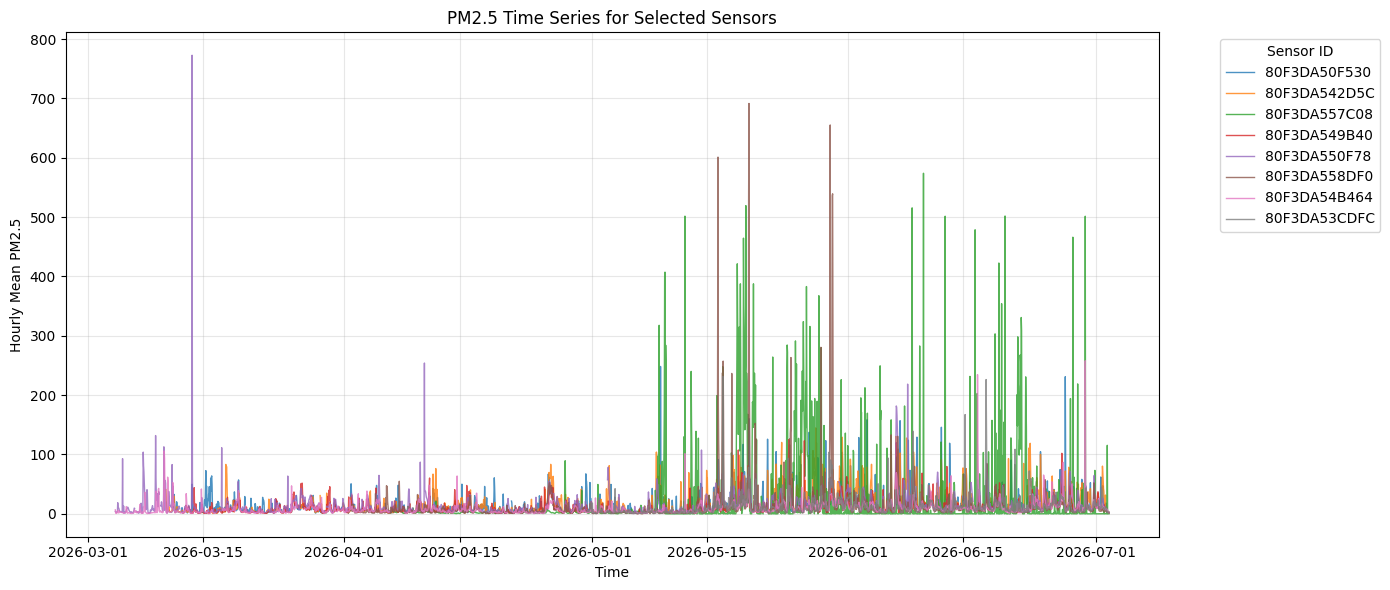

In [20]:
# Visualize the PM2.5 time series for the selected sensors
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sensor_id in selected_sensors:
    temp = hourly[hourly["sensor_id"] == sensor_id]

    plt.plot(
        temp["timestamp"],
        temp["pm2p5"],
        linewidth=1,
        alpha=0.8,
        label=str(sensor_id)
    )

plt.title("PM2.5 Time Series for Selected Sensors")
plt.xlabel("Time")
plt.ylabel("Hourly Mean PM2.5")
plt.legend(title="Sensor ID", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Example sensors time series graph with labels at the specific time there is a suspected spike based on the z_score constraint

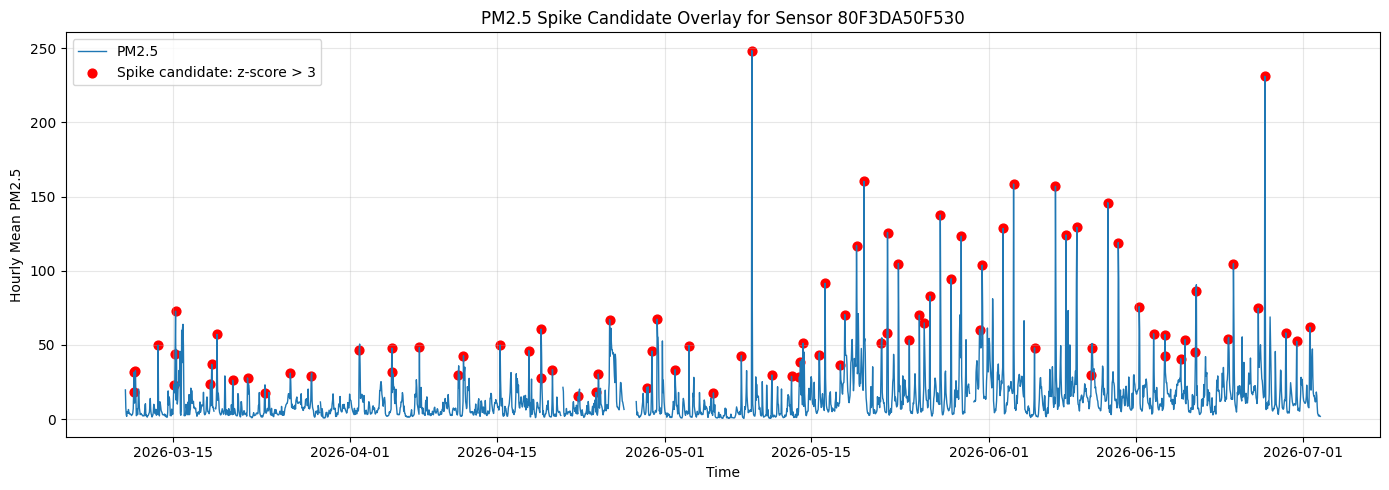

In [21]:
# spike candidate overlay
sensor_to_plot = selected_sensors[0]

temp = hourly[hourly["sensor_id"] == sensor_to_plot]
spikes = temp[
    (temp["z_score"] > 3) &
    (temp["pm2p5_diff"] >= 10) &
    (temp["reliable"]) &
    (temp["previous_reliable"])
]

plt.figure(figsize=(14, 5))

plt.plot(
    temp["timestamp"],
    temp["pm2p5"],
    linewidth=1,
    label="PM2.5"
)

plt.scatter(
    spikes["timestamp"],
    spikes["pm2p5"],
    color="red",
    s=40,
    label="Spike candidate: z-score > 3"
)

plt.title(f"PM2.5 Spike Candidate Overlay for Sensor {sensor_to_plot}")
plt.xlabel("Time")
plt.ylabel("Hourly Mean PM2.5")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# writing df_full to a CSV file
df_full.to_csv("sacaqm_80_sensors_full.csv", index=False)

In [23]:
# Check rows where both longitude and latitude are missing
df_null_coords = df_full[
    df_full["longitude"].isnull() & df_full["latitude"].isnull()
]

print(f"Number of rows with null coordinates: {len(df_null_coords)}")

# Show unique sensor IDs with missing coordinates
missing_sensors = (
    df_null_coords[["sensor_id", "longitude", "latitude"]]
    .drop_duplicates()
)

print(f"Number of unique sensors with null coordinates: {missing_sensors['sensor_id'].nunique()}")
print(missing_sensors)

Number of rows with null coordinates: 0
Number of unique sensors with null coordinates: 0
Empty DataFrame
Columns: [sensor_id, longitude, latitude]
Index: []


In [24]:
# drop these sensors from the df_full DataFrame
sensors_to_drop = missing_sensors["sensor_id"].tolist()
df_full = df_full.drop(df_full[df_full["sensor_id"].isin(sensors_to_drop)].index)

I dropped these because they don't have a station or a longitude and latitude value

## Grouping neighbourhood stations based on the distances between them. Boolean neighbourhood matrix shows which stations meet the "less than 5km" criteria. 'neighbours_within_5km' matrix allows us to see which sensors are neighbours.

In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import haversine_distances

# One row per sensor
station_coords = (
    df_full[["sensor_id", "station", "latitude", "longitude"]]
    .dropna(subset=["latitude", "longitude"])
    .drop_duplicates(subset=["sensor_id"]) # duplicate sensor_id rows due to time series data
    .reset_index(drop=True)
)

# Convert coordinates to radians
coords_rad = np.radians(
    station_coords[["latitude", "longitude"]].astype(float).values
)

# Distance matrix in km
dist_matrix = haversine_distances(coords_rad) * 6371

# Neighbour threshold
threshold_km = 5

# Boolean neighbour matrix
neighbour_matrix = dist_matrix < threshold_km
np.fill_diagonal(neighbour_matrix, False)

print(neighbour_matrix.shape)

(45, 45)


In [26]:
neighbour_df = pd.DataFrame(
    neighbour_matrix,
    index=station_coords["sensor_id"],
    columns=station_coords["sensor_id"]
)

neighbour_df.head()

sensor_id,80F3DA50B704,80F3DA50BD74,80F3DA50DE3C,80F3DA50DE58,80F3DA50E388,80F3DA50F2C0,80F3DA50F530,80F3DA539154,80F3DA53A570,80F3DA53CDFC,...,80F3DA551440,80F3DA5573F8,80F3DA557C08,80F3DA557E14,80F3DA5580BC,80F3DA558BC0,80F3DA558DF0,80F3DA5595B8,80F3DA559B2C,80F3DA55B134
sensor_id,,,,,,,,,,,,,,,,,,,,,
80F3DA50B704,False,False,False,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
80F3DA50BD74,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
80F3DA50DE3C,False,False,False,False,True,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
80F3DA50DE58,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
80F3DA50E388,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [27]:
neighbour_rows = []

for i, sensor_id in enumerate(station_coords["sensor_id"]):
    neighbour_indices = np.where(neighbour_matrix[i])[0]

    for j in neighbour_indices:
        neighbour_rows.append({
            "sensor_id": sensor_id,
            "station": station_coords.loc[i, "station"],
            "neighbour_sensor_id": station_coords.loc[j, "sensor_id"],
            "neighbour_station": station_coords.loc[j, "station"],
            "distance_km": dist_matrix[i, j]
        })

neighbours_within_5km = pd.DataFrame(neighbour_rows)

neighbours_within_5km.head(20)

,sensor_id,station,neighbour_sensor_id,neighbour_station,distance_km
0,80F3DA50B704,Montgomery Park Node 1,80F3DA50DE58,Northwold Drive,4.383942
1,80F3DA50B704,Montgomery Park Node 1,80F3DA53D73C,Parkhurst 1,3.495640
2,80F3DA50B704,Montgomery Park Node 1,80F3DA53FFDC,Parkhurst 2,3.950889
3,80F3DA50B704,Montgomery Park Node 1,80F3DA540038,Victory Park 1,3.927428
4,80F3DA50B704,Montgomery Park Node 1,80F3DA547384,NorthCliff,4.580760
5,80F3DA50B704,Montgomery Park Node 1,80F3DA557E14,Westdene 2,2.622553
6,80F3DA50BD74,Gstad South,80F3DA53A570,Vlakfontein 599,4.091257
7,80F3DA50BD74,Gstad South,80F3DA546CB8,Gstad West,0.983162
8,80F3DA50DE3C,Benmore Gardens,80F3DA50E388,Blairgowrie,4.678077
9,80F3DA50DE3C,Benmore Gardens,80F3DA50F2C0,CMCNetworks Woodmead,4.910253


In [28]:
neighbour_counts = (
    neighbours_within_5km
    .groupby(["sensor_id", "station"])
    .size()
    .reset_index(name="num_neighbours_within_5km")
    .sort_values("num_neighbours_within_5km", ascending=False)
)

neighbour_counts.head(20)

,sensor_id,station,num_neighbours_within_5km
0,80F3DA50B704,Montgomery Park Node 1,6
12,80F3DA53FFDC,Parkhurst 2,5
13,80F3DA540038,Victory Park 1,5
9,80F3DA53D73C,Parkhurst 1,5
4,80F3DA50E388,Blairgowrie,4
3,80F3DA50DE58,Northwold Drive,4
2,80F3DA50DE3C,Benmore Gardens,3
18,80F3DA547384,NorthCliff,3
5,80F3DA50F2C0,CMCNetworks Woodmead,2
11,80F3DA53E828,SYNERGIA Leeds 9,2


## Plotting a graph showing neighbours specifically in the Gauteng region, just as an observation.

In [29]:
# Rough Gauteng bounding box
gauteng_mask = (
    (station_coords["longitude"] >= 27.0) &
    (station_coords["longitude"] <= 29.5) &
    (station_coords["latitude"] >= -27.0) &
    (station_coords["latitude"] <= -25.0)
)

gauteng_coords = station_coords[gauteng_mask].reset_index(drop=True)

print("Number of Gauteng-area sensors:", len(gauteng_coords))

Number of Gauteng-area sensors: 35


In [30]:
# Compute distance matrix and neighbour matrix for Gauteng sensors
from sklearn.metrics.pairwise import haversine_distances

coords_rad_gauteng = np.radians(
    gauteng_coords[["latitude", "longitude"]].astype(float).values
)

dist_matrix_gauteng = haversine_distances(coords_rad_gauteng) * 6371

threshold_km = 5
neighbour_matrix_gauteng = dist_matrix_gauteng < threshold_km
np.fill_diagonal(neighbour_matrix_gauteng, False)

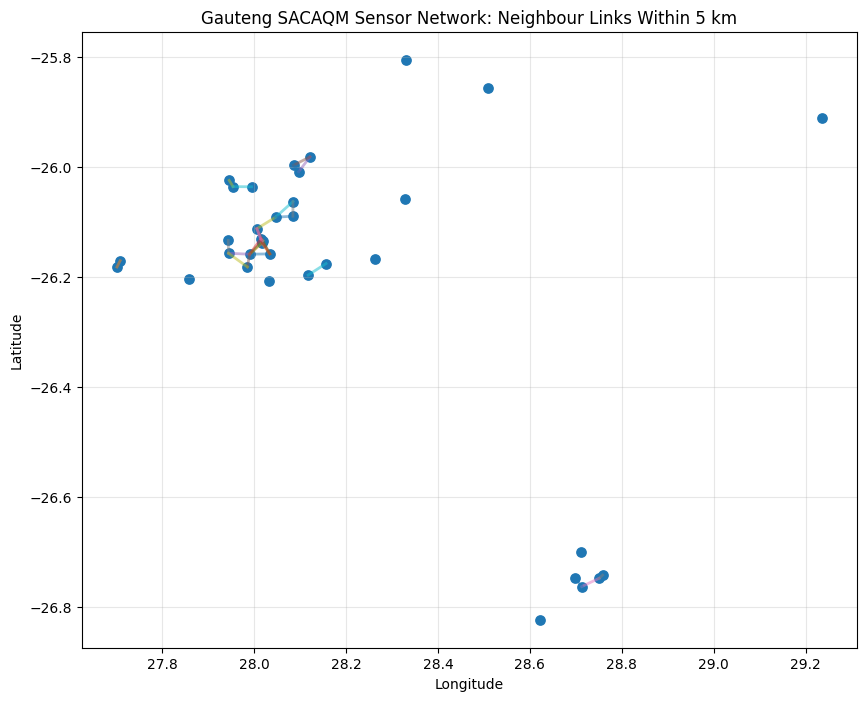

In [31]:
plt.figure(figsize=(10, 8))

plt.scatter(
    gauteng_coords["longitude"],
    gauteng_coords["latitude"],
    s=45
)

for i in range(len(gauteng_coords)):
    for j in range(i + 1, len(gauteng_coords)):
        if neighbour_matrix_gauteng[i, j]:
            plt.plot(
                [gauteng_coords.loc[i, "longitude"], gauteng_coords.loc[j, "longitude"]],
                [gauteng_coords.loc[i, "latitude"], gauteng_coords.loc[j, "latitude"]],
                linewidth=2,
                alpha=0.5
            )

plt.title("Gauteng SACAQM Sensor Network: Neighbour Links Within 5 km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.show()

## Getting the durations of the spike candidates; will use 'spike_durations' as another feature

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Start from the full hourly dataframe
# --------------------------------------------------

spike_df = hourly.copy()

# Make sure timestamp is datetime
spike_df["timestamp"] = pd.to_datetime(spike_df["timestamp"])

# Sort by sensor and time
spike_df = spike_df.sort_values(
    ["sensor_id", "timestamp"]
).reset_index(drop=True)

# --------------------------------------------------
# 2. Create spike flag
# Replace this with your final spike detection rule
# --------------------------------------------------
spike_df["is_spike"] = (
    (spike_df["z_score"] > 3) &
    (spike_df["pm2p5_diff"] >= 10) &
    (spike_df["reliable"]) &
    (spike_df["previous_reliable"])
)

# --------------------------------------------------
# 3. Identify where each new spike event starts
# --------------------------------------------------
spike_df["prev_is_spike"] = (
    spike_df
    .groupby("sensor_id")["is_spike"]
    .shift(fill_value=False)
)

spike_df["new_spike_event"] = (
    spike_df["is_spike"] &
    (~spike_df["prev_is_spike"])
)

# --------------------------------------------------
# 4. Assign an event ID to each spike event
# --------------------------------------------------
spike_df["spike_event_id"] = (
    spike_df
    .groupby("sensor_id")["new_spike_event"]
    .cumsum()
)

# --------------------------------------------------
# 5. Keep only spike rows
# --------------------------------------------------
spike_rows = spike_df[spike_df["is_spike"]].copy()

# --------------------------------------------------
# 6. Summarise each spike event
# --------------------------------------------------
spike_events = (
    spike_rows
    .groupby(["sensor_id", "spike_event_id"])
    .agg(
        station=("station", "first"),
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        duration_timesteps=("timestamp", "size"),
        max_pm2p5=("pm2p5", "max"),
        mean_pm2p5=("pm2p5", "mean"),
        max_z_score=("z_score", "max"),
        mean_z_score=("z_score", "mean"),
        min_actual_readings=("actual_readings", "min"),
        mean_actual_readings=("actual_readings", "mean")
    )
    .reset_index()
)

# If your data is hourly, timesteps are approximately hours
spike_events["duration_hours"] = spike_events["duration_timesteps"]

print("Number of detected spike events:", len(spike_events))
display(spike_events.head())



Number of detected spike events: 868


,sensor_id,spike_event_id,station,start_time,end_time,duration_timesteps,max_pm2p5,mean_pm2p5,max_z_score,mean_z_score,min_actual_readings,mean_actual_readings,duration_hours
0,80F3DA50B704,1,Montgomery Park Node 1,2026-03-17 16:00:00,2026-03-17 16:00:00,1,14.230000,14.230000,3.291940,3.291940,10,10.0,1
1,80F3DA50B704,2,Montgomery Park Node 1,2026-03-17 21:00:00,2026-03-17 21:00:00,1,23.250000,23.250000,6.360502,6.360502,12,12.0,1
2,80F3DA50B704,3,Montgomery Park Node 1,2026-03-19 01:00:00,2026-03-19 02:00:00,2,47.490909,33.507955,12.138528,9.512753,11,11.5,2
3,80F3DA50B704,4,Montgomery Park Node 1,2026-03-26 04:00:00,2026-03-26 04:00:00,1,56.408333,56.408333,4.358905,4.358905,12,12.0,1
4,80F3DA50B704,5,Montgomery Park Node 1,2026-04-03 03:00:00,2026-04-03 03:00:00,1,48.041667,48.041667,6.038582,6.038582,12,12.0,1


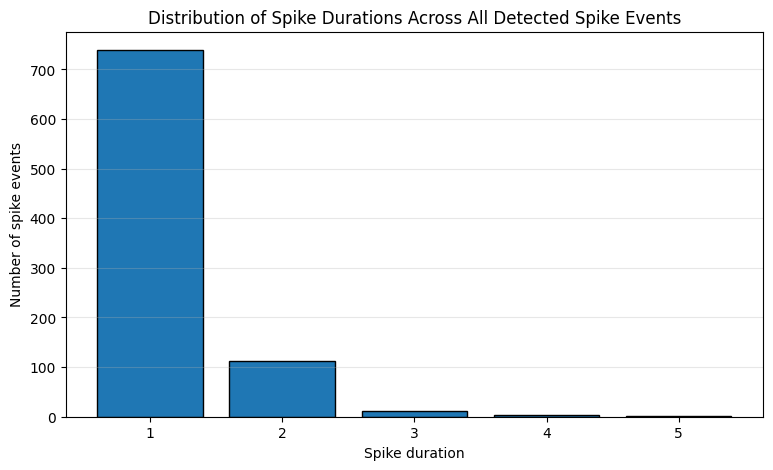

In [33]:
# --------------------------------------------------
#   Plot duration distribution
# --------------------------------------------------
duration_counts = (
    spike_events["duration_timesteps"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    duration_counts.index,
    duration_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Spike Durations Across All Detected Spike Events")
plt.xlabel("Spike duration")
plt.ylabel("Number of spike events")
plt.xticks(duration_counts.index)
plt.grid(True, axis="y", alpha=0.3)

plt.show()

For every row in spike_candidates, we will ask:

1. Did this candidate last more than 1 timestep?
2. Which sensors are within 5 km of this sensor?
3. Did any of those neighbouring sensors also have a spike event at the same timestamp?
4. Did the neighbour spike have the same duration?
5. Based on that, should we label the spike as real or fake?


If target spike duration > 1
AND at least one neighbour within 5 km has a spike at the same timestamp
AND the neighbour has the same duration
THEN label = real

In [34]:
# Make clean copies
spike_candidates = spike_candidates.copy()

spike_events_duration  = spike_events[[
    "sensor_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps",
    "max_pm2p5",
    "mean_pm2p5"
]].copy()

# Clean sensor IDs
spike_candidates["sensor_id"] = spike_candidates["sensor_id"].astype(str).str.strip().str.upper()
spike_events_duration["sensor_id"] = spike_events_duration["sensor_id"].astype(str).str.strip().str.upper()

# Make sure datetime columns are actually datetime
spike_candidates["timestamp"] = pd.to_datetime(spike_candidates["timestamp"])
spike_events_duration["start_time"] = pd.to_datetime(spike_events_duration["start_time"])
spike_events_duration["end_time"] = pd.to_datetime(spike_events_duration["end_time"])

# Create a unique ID for each spike candidate row
spike_candidates["_candidate_id"] = range(len(spike_candidates))

# Merge candidates with all possible events from the same sensor
candidate_event_matches = spike_candidates[[
    "_candidate_id",
    "sensor_id",
    "timestamp"
]].merge(
    spike_events_duration,
    on="sensor_id",
    how="left"
)

# Keep only the event where the candidate timestamp falls inside the event window
candidate_event_matches = candidate_event_matches[
    (candidate_event_matches["timestamp"] >= candidate_event_matches["start_time"]) &
    (candidate_event_matches["timestamp"] <= candidate_event_matches["end_time"])
].copy()

# In case there are duplicate matches, keep one event per candidate
candidate_event_matches = candidate_event_matches.drop_duplicates(
    subset=["_candidate_id"]
)

# Select the event-level features to attach back to spike_candidates
event_features = candidate_event_matches[[
    "_candidate_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps",
    "max_pm2p5",
    "mean_pm2p5"
]].rename(columns={
    "start_time": "event_start_time",
    "end_time": "event_end_time",
    "max_pm2p5": "event_max_pm2p5",
    "mean_pm2p5": "event_mean_pm2p5"
})

# Merge event duration/features back into spike_candidates
spike_candidates = spike_candidates.merge(
    event_features,
    on="_candidate_id",
    how="left"
)

# Remove helper column
spike_candidates = spike_candidates.drop(columns=["_candidate_id"])

spike_candidates.head()

,sensor_id,station,timestamp,pm2p5,actual_readings,expected_readings,reliable,pm2p5_for_stats,rolling_mean,rolling_std,rolling_std_safe,z_score,pm2p5_diff,previous_reliable,spike_event_id,event_start_time,event_end_time,duration_timesteps,event_max_pm2p5,event_mean_pm2p5
0,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425000,12,12,True,400.425000,3.721907,1.768754,2.000000,198.351547,394.766667,True,37,2026-06-26 22:00:00,2026-06-26 22:00:00,1,400.425000,400.425000
1,80F3DA551440,SYNERGIA Leeds 4,2026-03-29 19:00:00,320.966667,12,12,True,320.966667,2.350362,1.770876,2.000000,159.308152,318.833333,True,7,2026-03-29 19:00:00,2026-03-29 19:00:00,1,320.966667,320.966667
2,80F3DA551440,SYNERGIA Leeds 4,2026-04-14 14:00:00,184.763636,11,12,True,184.763636,2.720391,2.049975,2.049975,88.802684,182.788636,True,11,2026-04-14 14:00:00,2026-04-14 14:00:00,1,184.763636,184.763636
3,80F3DA551440,SYNERGIA Leeds 4,2026-06-09 14:00:00,513.033333,12,12,True,513.033333,2.183902,5.980693,5.980693,85.416422,512.200000,True,30,2026-06-09 14:00:00,2026-06-09 14:00:00,1,513.033333,513.033333
4,80F3DA547384,NorthCliff,2026-03-22 04:00:00,151.366667,12,12,True,151.366667,3.211711,1.988720,2.000000,74.077478,147.508333,True,6,2026-03-22 04:00:00,2026-03-22 07:00:00,4,314.016667,236.580303


In [35]:
neighbours = neighbours_within_5km[["sensor_id", "neighbour_sensor_id", "distance_km"]].copy()
spike_events_clean = spike_events.copy()
spike_candidates_clean = spike_candidates.copy()
# Clean sensor IDs
neighbours["sensor_id"] = neighbours["sensor_id"].astype(str).str.strip().str.upper()
neighbours["neighbour_sensor_id"] = neighbours["neighbour_sensor_id"].astype(str).str.strip().str.upper()
spike_candidates["sensor_id"] = spike_candidates["sensor_id"].astype(str).str.strip().str.upper()
spike_events_clean["sensor_id"] = spike_events_clean["sensor_id"].astype(str).str.strip().str.upper()

# Standardise timestamps
spike_candidates["timestamp"] = pd.to_datetime(spike_candidates["timestamp"])
spike_events_clean["start_time"] = pd.to_datetime(spike_events_clean["start_time"])
spike_events_clean["end_time"] = pd.to_datetime(spike_events_clean["end_time"])

Merging sensors with spike candidates with their neighbours

In [36]:
# spike candidates get unique ids because when merging with neighbours, we want to keep all rows even if they have the same sensor_id and timestamp
spike_candidates = spike_candidates.reset_index(drop=True)
spike_candidates["candidate_id"] = spike_candidates.index

# rename target duration column for clarity
spike_candidates = spike_candidates.rename(columns={
    "duration_timesteps": "target_duration_timesteps"
})

candidate_neighbour_pairs = spike_candidates.merge(
    neighbours,
    on="sensor_id",
    how="left"
)

candidate_neighbour_pairs.head(20)

,sensor_id,station,timestamp,pm2p5,actual_readings,expected_readings,reliable,pm2p5_for_stats,rolling_mean,rolling_std,...,previous_reliable,spike_event_id,event_start_time,event_end_time,target_duration_timesteps,event_max_pm2p5,event_mean_pm2p5,candidate_id,neighbour_sensor_id,distance_km
0,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425000,12,12,True,400.425000,3.721907,1.768754,...,True,37,2026-06-26 22:00:00,2026-06-26 22:00:00,1,400.425000,400.425000,0,80F3DA5580BC,0.042139
1,80F3DA551440,SYNERGIA Leeds 4,2026-03-29 19:00:00,320.966667,12,12,True,320.966667,2.350362,1.770876,...,True,7,2026-03-29 19:00:00,2026-03-29 19:00:00,1,320.966667,320.966667,1,80F3DA5580BC,0.042139
2,80F3DA551440,SYNERGIA Leeds 4,2026-04-14 14:00:00,184.763636,11,12,True,184.763636,2.720391,2.049975,...,True,11,2026-04-14 14:00:00,2026-04-14 14:00:00,1,184.763636,184.763636,2,80F3DA5580BC,0.042139
3,80F3DA551440,SYNERGIA Leeds 4,2026-06-09 14:00:00,513.033333,12,12,True,513.033333,2.183902,5.980693,...,True,30,2026-06-09 14:00:00,2026-06-09 14:00:00,1,513.033333,513.033333,3,80F3DA5580BC,0.042139
4,80F3DA547384,NorthCliff,2026-03-22 04:00:00,151.366667,12,12,True,151.366667,3.211711,1.988720,...,True,6,2026-03-22 04:00:00,2026-03-22 07:00:00,4,314.016667,236.580303,4,80F3DA50B704,4.580760
5,80F3DA547384,NorthCliff,2026-03-22 04:00:00,151.366667,12,12,True,151.366667,3.211711,1.988720,...,True,6,2026-03-22 04:00:00,2026-03-22 07:00:00,4,314.016667,236.580303,4,80F3DA5474CC,2.618357
6,80F3DA547384,NorthCliff,2026-03-22 04:00:00,151.366667,12,12,True,151.366667,3.211711,1.988720,...,True,6,2026-03-22 04:00:00,2026-03-22 07:00:00,4,314.016667,236.580303,4,80F3DA557E14,4.947436
7,80F3DA557C08,Welgemoed,2026-05-12 04:00:00,129.727273,11,12,True,129.727273,0.085417,0.418454,...,True,10,2026-05-12 04:00:00,2026-05-12 04:00:00,1,129.727273,129.727273,5,NaN,NaN
8,80F3DA546CB8,Gstad West,2026-06-17 22:00:00,492.041667,12,12,True,492.041667,10.455429,8.119311,...,True,10,2026-06-17 22:00:00,2026-06-17 22:00:00,1,492.041667,492.041667,6,80F3DA50BD74,0.983162
9,80F3DA557C08,Welgemoed,2026-07-02 10:00:00,115.383333,12,12,True,115.383333,0.307386,1.410256,...,True,54,2026-07-02 10:00:00,2026-07-02 10:00:00,1,115.383333,115.383333,7,NaN,NaN


In [37]:
neighbour_hourly_status = hourly[
    ["sensor_id", "timestamp", "reliable", "actual_readings"]
].copy()

neighbour_hourly_status = neighbour_hourly_status.rename(columns={
    "sensor_id": "neighbour_sensor_id",
    "reliable": "neighbour_reliable_at_time",
    "actual_readings": "neighbour_actual_readings_at_time"
})

candidate_neighbour_pairs = candidate_neighbour_pairs.merge(
    neighbour_hourly_status,
    on=["neighbour_sensor_id", "timestamp"],
    how="left"
)

candidate_neighbour_pairs["neighbour_reliable_at_time"] = (
    candidate_neighbour_pairs["neighbour_reliable_at_time"]
    .fillna(False)
)

C:\Users\okwuk\AppData\Local\Temp\ipykernel_16116\2394219844.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [38]:
# if a sensor has no neighbours within 5 km, you should not confidently call it fake. You simply do not have enough spatial evidence.
neighbour_counts = (
    candidate_neighbour_pairs[candidate_neighbour_pairs["neighbour_reliable_at_time"]] # neighbour has to have reliable readings at the same time as the candidate spike
    .groupby("candidate_id")
    .agg(
        n_neighbours_checked=("neighbour_sensor_id", "nunique")
    )
    .reset_index()
)

neighbour_counts.head(5)

,candidate_id,n_neighbours_checked
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1


In [39]:
neighbour_events = spike_events_clean[[
    "sensor_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps"
]].copy()

neighbour_events = neighbour_events.rename(columns={
    "sensor_id": "neighbour_sensor_id",
    "spike_event_id": "neighbour_spike_event_id",
    "start_time": "neighbour_start_time",
    "end_time": "neighbour_end_time",
    "duration_timesteps": "neighbour_duration_timesteps"
})

neighbour_events.head(20)

,neighbour_sensor_id,neighbour_spike_event_id,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps
0,80F3DA50B704,1,2026-03-17 16:00:00,2026-03-17 16:00:00,1
1,80F3DA50B704,2,2026-03-17 21:00:00,2026-03-17 21:00:00,1
2,80F3DA50B704,3,2026-03-19 01:00:00,2026-03-19 02:00:00,2
3,80F3DA50B704,4,2026-03-26 04:00:00,2026-03-26 04:00:00,1
4,80F3DA50B704,5,2026-04-03 03:00:00,2026-04-03 03:00:00,1
5,80F3DA50B704,6,2026-04-04 18:00:00,2026-04-04 18:00:00,1
6,80F3DA50B704,7,2026-04-07 20:00:00,2026-04-07 20:00:00,1
7,80F3DA50B704,8,2026-04-10 02:00:00,2026-04-10 02:00:00,1
8,80F3DA50B704,9,2026-04-10 04:00:00,2026-04-10 04:00:00,1
9,80F3DA50B704,10,2026-04-11 06:00:00,2026-04-11 06:00:00,1


In [40]:
# merge candidate_neighbour_pairs with neighbour_events to get the duration of the neighbour events
candidate_neighbour_events = candidate_neighbour_pairs.merge(
    neighbour_events,
    on="neighbour_sensor_id",
    how="left"
)

candidate_neighbour_events.head(5)

,sensor_id,station,timestamp,pm2p5,actual_readings,expected_readings,reliable,pm2p5_for_stats,rolling_mean,rolling_std,...,event_mean_pm2p5,candidate_id,neighbour_sensor_id,distance_km,neighbour_reliable_at_time,neighbour_actual_readings_at_time,neighbour_spike_event_id,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps
0,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425,12,12,True,400.425,3.721907,1.768754,...,400.425,0,80F3DA5580BC,0.042139,True,12.0,1.0,2026-03-04 22:00:00,2026-03-05 00:00:00,3.0
1,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425,12,12,True,400.425,3.721907,1.768754,...,400.425,0,80F3DA5580BC,0.042139,True,12.0,2.0,2026-03-08 07:00:00,2026-03-08 07:00:00,1.0
2,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425,12,12,True,400.425,3.721907,1.768754,...,400.425,0,80F3DA5580BC,0.042139,True,12.0,3.0,2026-03-09 05:00:00,2026-03-09 05:00:00,1.0
3,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425,12,12,True,400.425,3.721907,1.768754,...,400.425,0,80F3DA5580BC,0.042139,True,12.0,4.0,2026-03-20 05:00:00,2026-03-20 06:00:00,2.0
4,80F3DA551440,SYNERGIA Leeds 4,2026-06-26 22:00:00,400.425,12,12,True,400.425,3.721907,1.768754,...,400.425,0,80F3DA5580BC,0.042139,True,12.0,5.0,2026-03-20 09:00:00,2026-03-20 09:00:00,1.0


The target sensor spiked at this timestamp.
Was the neighbour also inside a spike event at that same timestamp?

In [41]:
# Keep only the rows where the candidate timestamp falls within the neighbour event window
active_neighbour_events = candidate_neighbour_events[
    (candidate_neighbour_events["timestamp"] >= candidate_neighbour_events["neighbour_start_time"]) &
    (candidate_neighbour_events["timestamp"] <= candidate_neighbour_events["neighbour_end_time"])
].copy()

### REAL CONDITION: A spike candidate is confirmed as real if at least one neighbouring sensor within 5 km also records an active spike at the same timestamp, and the neighbour spike duration is within ±1 timestep of the target spike duration.

In [42]:
# Duration closeness rule
# For hourly data, allow neighbour duration to differ by at most 1 timestep/hour
duration_tolerance = 1

active_neighbour_events["duration_close_match"] = (
    active_neighbour_events["target_duration_timesteps"].ge(1) &
    active_neighbour_events["neighbour_duration_timesteps"].ge(1) &
    (
        abs(
            active_neighbour_events["target_duration_timesteps"] -
            active_neighbour_events["neighbour_duration_timesteps"]
        ) <= duration_tolerance
    )
)

active_neighbour_events[
    [
        "candidate_id",
        "sensor_id",
        "timestamp",
        "target_duration_timesteps",
        "neighbour_sensor_id",
        "distance_km",
        "neighbour_start_time",
        "neighbour_end_time",
        "neighbour_duration_timesteps",
        "duration_close_match"
    ]
].head(5)



,candidate_id,sensor_id,timestamp,target_duration_timesteps,neighbour_sensor_id,distance_km,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps,duration_close_match
233,20,80F3DA558DF0,2026-05-20 00:00:00,2,80F3DA53CDFC,1.452454,2026-05-20 00:00:00,2026-05-20 00:00:00,1.0,True
981,64,80F3DA53A570,2026-06-17 12:00:00,1,80F3DA50BD74,4.091257,2026-06-17 12:00:00,2026-06-17 12:00:00,1.0,True
1001,64,80F3DA53A570,2026-06-17 12:00:00,1,80F3DA54C238,2.250298,2026-06-17 12:00:00,2026-06-17 12:00:00,1.0,True
1384,84,80F3DA549B40,2026-05-18 18:00:00,1,80F3DA549348,4.527209,2026-05-18 18:00:00,2026-05-18 18:00:00,1.0,True
1599,93,80F3DA54C238,2026-06-20 10:00:00,1,80F3DA53A570,2.250298,2026-06-20 10:00:00,2026-06-20 11:00:00,2.0,True


### General Evidence
*n_neighbours_checked*:
How many nearby sensors were available?

*n_active_neighbour_spikes*:
How many nearby sensors were also spiking at that timestamp?

*n_same_duration_neighbours*:
How many nearby sensors had the same spike duration?

In [43]:
neighbour_counts = (
    candidate_neighbour_pairs[candidate_neighbour_pairs["neighbour_reliable_at_time"]]
    .groupby("candidate_id")
    .agg(
        n_neighbours_checked=("neighbour_sensor_id", "nunique")
    )
    .reset_index()
)

active_neighbour_summary = (
    active_neighbour_events
    .groupby("candidate_id")
    .agg(
        n_active_neighbour_spikes=("neighbour_sensor_id", "nunique"),
        max_neighbour_duration=("neighbour_duration_timesteps", "max"),
        mean_neighbour_duration=("neighbour_duration_timesteps", "mean")
    )
    .reset_index()
)

close_duration_summary = (
    active_neighbour_events[active_neighbour_events["duration_close_match"]]
    .groupby("candidate_id")
    .agg(
        n_close_duration_neighbours=("neighbour_sensor_id", "nunique"),
        close_duration_neighbour_ids=("neighbour_sensor_id", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

In [44]:
labelled_spike_candidates = spike_candidates.merge(
    neighbour_counts,
    on="candidate_id",
    how="left"
)

labelled_spike_candidates = labelled_spike_candidates.merge(
    active_neighbour_summary,
    on="candidate_id",
    how="left"
)

labelled_spike_candidates = labelled_spike_candidates.merge(
    close_duration_summary,
    on="candidate_id",
    how="left"
)

# Fill missing evidence with 0
fill_cols = [
    "n_neighbours_checked",
    "n_active_neighbour_spikes",
    "n_close_duration_neighbours",
    "max_neighbour_duration",
    "mean_neighbour_duration"
]

for col in fill_cols:
    labelled_spike_candidates[col] = labelled_spike_candidates[col].fillna(0)

labelled_spike_candidates["close_duration_neighbour_ids"] = (
    labelled_spike_candidates["close_duration_neighbour_ids"].fillna("")
)

A spike is suspected fake if: 
1. neighbours exist within 5 km, 
2. none of the neighbours spike at the same timestamp, 
3. the spike is very short, for example 1 timestep, 
4. the spike has a sharp jump and immediate drop, 
5. the surrounding values return to normal quickly, 

Future improvement:
The event is not supported by any other pollutant feature or nearby sensor. (add other pollutants)

In [45]:
spike_df = spike_df.sort_values(["sensor_id", "timestamp"]).copy()

# Previous and next PM2.5 values
spike_df["prev_pm2p5"] = spike_df.groupby("sensor_id")["pm2p5"].shift(1)
spike_df["next_pm2p5"] = spike_df.groupby("sensor_id")["pm2p5"].shift(-1)

# Next-hour spike context
spike_df["next_z_score"] = spike_df.groupby("sensor_id")["z_score"].shift(-1)
spike_df["next_rolling_mean"] = spike_df.groupby("sensor_id")["rolling_mean"].shift(-1)
spike_df["next_rolling_std"] = spike_df.groupby("sensor_id")["rolling_std"].shift(-1)
spike_df["next_is_spike"] = spike_df.groupby("sensor_id")["is_spike"].shift(-1).fillna(False)

# Row at the end of each spike event
event_end_context = spike_df[[
    "sensor_id",
    "timestamp",
    "next_pm2p5",
    "next_z_score",
    "next_rolling_mean",
    "next_rolling_std",
    "next_is_spike"
]].rename(columns={
    "timestamp": "event_end_time"
})

# Merge next-hour context into labelled candidates
labelled_spike_candidates = labelled_spike_candidates.merge(
    event_end_context,
    on=["sensor_id", "event_end_time"],
    how="left"
)

C:\Users\okwuk\AppData\Local\Temp\ipykernel_16116\3406273296.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  spike_df["next_is_spike"] = spike_df.groupby("sensor_id")["is_spike"].shift(-1).fillna(False)


In [46]:
# --------------------------------------------------
# Suspected fake evidence features
# --------------------------------------------------

# A sharp jump means the PM2.5 increase is large relative to normal variation.
# The 10 unit minimum avoids tiny rolling_std values making the rule too sensitive.
jump_threshold = np.maximum(
    10,
    2 * labelled_spike_candidates["rolling_std"]
)

labelled_spike_candidates["sharp_jump"] = (
    labelled_spike_candidates["pm2p5_diff"] >= jump_threshold
)

# Sharp drop after the event
labelled_spike_candidates["drop_after_event"] = (
    labelled_spike_candidates["event_max_pm2p5"] -
    labelled_spike_candidates["next_pm2p5"]
)

labelled_spike_candidates["sharp_drop_after_event"] = (
    labelled_spike_candidates["drop_after_event"] >= jump_threshold
)

# Return to normal quickly means the next hour is no longer a spike
# and the next value is close to the rolling baseline.
labelled_spike_candidates["returns_to_normal_quickly"] = (
    (labelled_spike_candidates["next_is_spike"] == False) &
    (
        (labelled_spike_candidates["next_z_score"].abs() <= 1.5) |
        (
            labelled_spike_candidates["next_pm2p5"] <=
            labelled_spike_candidates["next_rolling_mean"] +
            labelled_spike_candidates["next_rolling_std"]
        )
    )
)

In [47]:
# --------------------------------------------------
# Suspected fake spike rule
# --------------------------------------------------

labelled_spike_candidates["suspected_fake"] = (
    # 1. Neighbours exist within 5 km
    (labelled_spike_candidates["n_neighbours_checked"] > 0) &

    # 2. None of the neighbours spike at the same timestamp
    (labelled_spike_candidates["n_active_neighbour_spikes"] == 0) &

    # 3. The spike is very short
    (labelled_spike_candidates["target_duration_timesteps"] == 1) &

    # 4. The spike has a sharp jump
    (labelled_spike_candidates["sharp_jump"]) &

    # 5. It drops and returns to normal quickly
    (labelled_spike_candidates["sharp_drop_after_event"]) &
    (labelled_spike_candidates["returns_to_normal_quickly"])
)

In [48]:
labelled_spike_candidates["suspected_fake"].value_counts()

suspected_fake
False    891
True     130
Name: count, dtype: int64

In [49]:
conditions = [
    # Strong real evidence
    labelled_spike_candidates["n_close_duration_neighbours"] >= 1,

    # Some real evidence, but duration differs
    (
        (labelled_spike_candidates["n_active_neighbour_spikes"] >= 1) &
        (labelled_spike_candidates["n_close_duration_neighbours"] == 0)
    ),

    # Strong fake-like evidence
    labelled_spike_candidates["suspected_fake"],

    # No neighbours available
    labelled_spike_candidates["n_neighbours_checked"] == 0,

    # Neighbours exist but no neighbour spike, without enough fake evidence
    (
        (labelled_spike_candidates["n_neighbours_checked"] > 0) &
        (labelled_spike_candidates["n_active_neighbour_spikes"] == 0)
    )
]

choices = [
    "confirmed_real_close_duration",
    "spatially_supported_different_duration",
    "suspected_fake_sensor_artifact",
    "unconfirmed_no_neighbours",
    "isolated_unconfirmed"
]

labelled_spike_candidates["rule_label"] = np.select(
    conditions,
    choices,
    default="unconfirmed"
)

labelled_spike_candidates["rule_label"].value_counts()

# confirmed_real_close_duration
# = neighbour spike exists and duration difference is 0 or 1 hour

# spatially_supported_duration_mismatch
# = neighbour spike exists but duration difference is more than 1 hour

rule_label
unconfirmed_no_neighbours                 404
isolated_unconfirmed                      387
suspected_fake_sensor_artifact            130
confirmed_real_close_duration              96
spatially_supported_different_duration      4
Name: count, dtype: int64

In [50]:
model_data = labelled_spike_candidates[
    labelled_spike_candidates["rule_label"].isin([
        "confirmed_real_close_duration",
        "spatially_supported_different_duration",
        "suspected_fake_sensor_artifact"
    ])
].copy()

model_data["ml_label"] = np.select(
    [
        model_data["rule_label"].isin([
            "confirmed_real_close_duration",
            "spatially_supported_different_duration"
        ]),
        model_data["rule_label"] == "suspected_fake_sensor_artifact"
    ],
    [
        "real",
        "suspected_fake"
    ],
    default="unconfirmed"
)

model_data["ml_label"].value_counts()
model_data.to_csv("sacaqm_spike_candidates_with_labels.csv", index=False)

### INSPECTING SUSPECTED FAKE SENSOR CHARACTERISTICS

In [51]:
# filter only to rows with suspected_fake
fake_spikes = labelled_spike_candidates[
    labelled_spike_candidates["rule_label"] == "suspected_fake_sensor_artifact"
]

fake_spikes[
    [
        "candidate_id",
        "sensor_id",
        "station",
        "timestamp",
        "spike_event_id",
        "target_duration_timesteps",
        "pm2p5",
        "rolling_mean",
        "rolling_std",
        "z_score",
        "pm2p5_diff",
        "n_neighbours_checked",
        "n_active_neighbour_spikes",
        "n_close_duration_neighbours",
        "sharp_jump",
        "sharp_drop_after_event",
        "returns_to_normal_quickly",
        "suspected_fake",
        "rule_label"
    ]
].sort_values(["sensor_id", "timestamp"]).head(20)


,candidate_id,sensor_id,station,timestamp,spike_event_id,target_duration_timesteps,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,n_neighbours_checked,n_active_neighbour_spikes,n_close_duration_neighbours,sharp_jump,sharp_drop_after_event,returns_to_normal_quickly,suspected_fake,rule_label
931,931,80F3DA50B704,Montgomery Park Node 1,2026-03-17 16:00:00,1,1,14.230000,4.106061,3.075372,3.291940,11.396667,3.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
683,683,80F3DA50B704,Montgomery Park Node 1,2026-03-26 04:00:00,4,1,56.408333,10.254324,10.588442,4.358905,32.608333,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
116,116,80F3DA50B704,Montgomery Park Node 1,2026-04-04 18:00:00,6,1,60.508333,6.407481,4.063987,13.312260,55.916667,3.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
593,593,80F3DA50B704,Montgomery Park Node 1,2026-04-29 07:00:00,15,1,43.825000,8.492622,7.305462,4.836433,20.650000,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
327,327,80F3DA50B704,Montgomery Park Node 1,2026-05-13 19:00:00,19,1,21.408333,1.894918,2.747151,7.103146,15.333333,4.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
384,384,80F3DA50B704,Montgomery Park Node 1,2026-05-25 03:00:00,22,1,29.283333,4.066414,3.876262,6.505474,27.808333,5.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
893,893,80F3DA50BD74,Gstad South,2026-06-15 09:00:00,3,1,36.458333,14.786458,6.290505,3.445173,17.941667,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
202,202,80F3DA50DE58,Northwold Drive,2026-03-30 02:00:00,5,1,38.125000,3.217622,3.514889,9.931288,22.425000,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
928,928,80F3DA50DE58,Northwold Drive,2026-04-15 12:00:00,8,1,19.050000,8.337708,3.239258,3.307020,12.583333,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact
580,580,80F3DA50DE58,Northwold Drive,2026-04-27 22:00:00,11,1,36.866667,6.617582,6.155266,4.914343,19.466667,2.0,0.0,0.0,True,True,True,True,suspected_fake_sensor_artifact


In [52]:
def plot_spike_window(candidate_id, window_hours=12):
    row = fake_spikes[fake_spikes["candidate_id"] == candidate_id].iloc[0]

    sensor_id = row["sensor_id"]
    spike_time = row["timestamp"]

    window_start = spike_time - pd.Timedelta(hours=12)
    window_end = spike_time + pd.Timedelta(hours=12)

    plot_df = hourly[
        (hourly["sensor_id"] == sensor_id) &
        (hourly["timestamp"] >= window_start) &
        (hourly["timestamp"] <= window_end)
    ].copy()

    plot_df = plot_df.sort_values("timestamp")

    plt.figure(figsize=(12, 4))

    plt.plot(
        plot_df["timestamp"],
        plot_df["pm2p5"],
        marker="o",
        label="PM2.5"
    )

    if "rolling_mean" in plot_df.columns:
        plt.plot(
            plot_df["timestamp"],
            plot_df["rolling_mean"],
            linestyle="--",
            label="Rolling mean"
        )

    plt.axvline(
        spike_time,
        linestyle=":",
        label="Suspected fake spike"
    )

    plt.title(f"Candidate {candidate_id} | Sensor {sensor_id}")
    plt.xlabel("Timestamp")
    plt.ylabel("PM2.5")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()



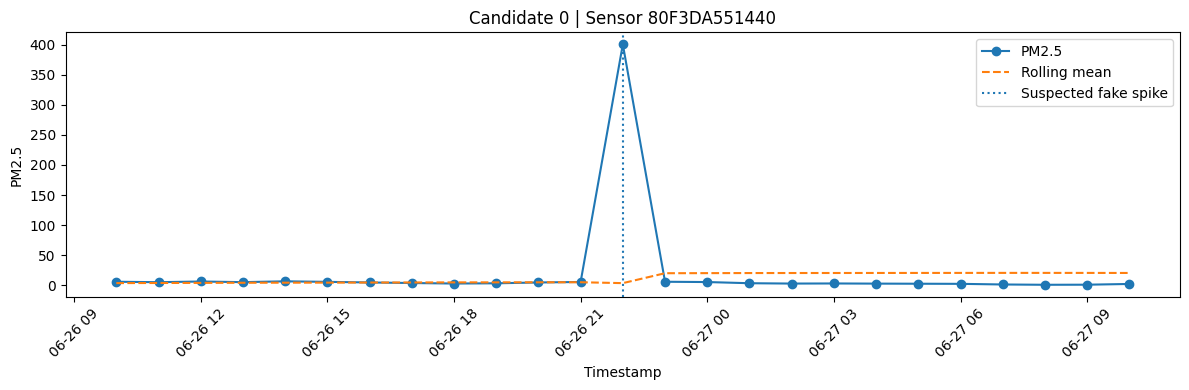

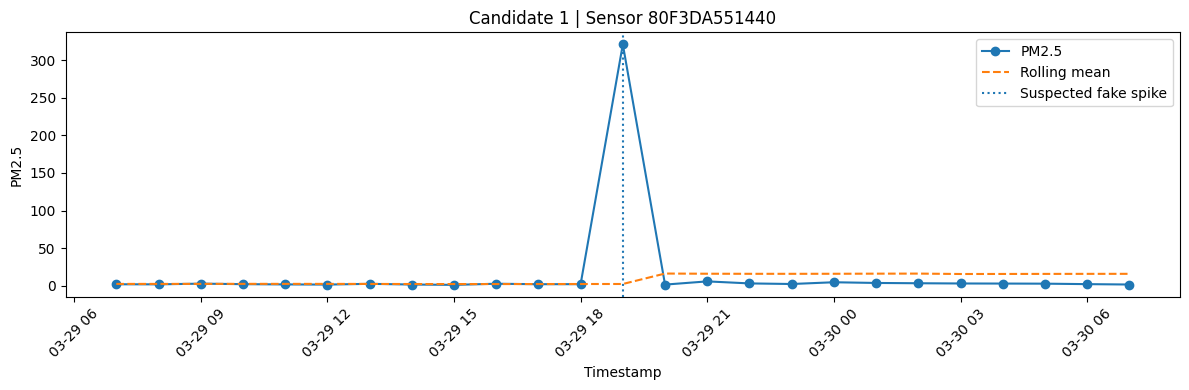

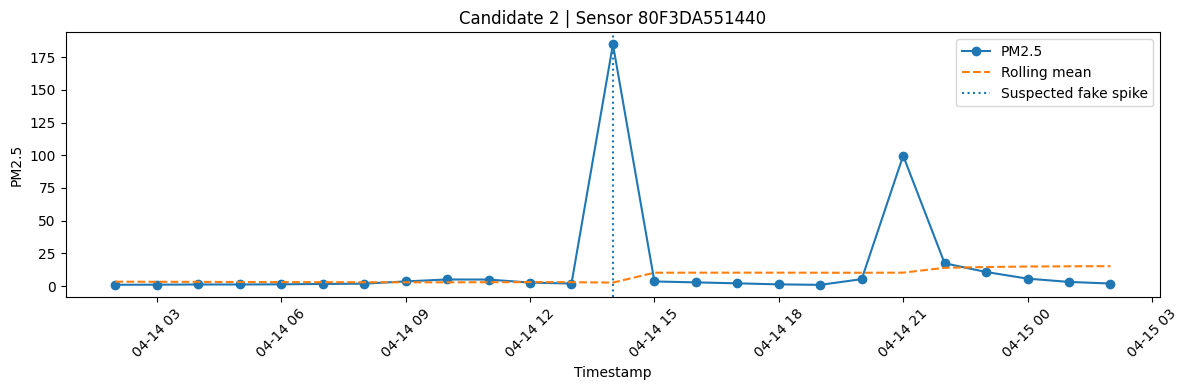

In [53]:
for candidate_id in fake_spikes["candidate_id"].head(3):
    plot_spike_window(candidate_id)

### INSPECTING SUSPECTED REAL SPIKES

In [54]:
real_spikes = labelled_spike_candidates[
    labelled_spike_candidates["rule_label"].isin(["confirmed_real_close_duration",
            "spatially_supported_different_duration"])
]

real_spikes[
    [
        "candidate_id",
        "sensor_id",
        "station",
        "timestamp",
        "spike_event_id",
        "target_duration_timesteps",
        "pm2p5",
        "rolling_mean",
        "rolling_std",
        "z_score",
        "pm2p5_diff",
        "n_neighbours_checked",
        "n_active_neighbour_spikes",
        "n_close_duration_neighbours",
        "sharp_jump",
        "sharp_drop_after_event",
        "returns_to_normal_quickly",
        "suspected_fake",
        "rule_label"
    ]
].sort_values(["sensor_id", "timestamp"]).head(25)

,candidate_id,sensor_id,station,timestamp,spike_event_id,target_duration_timesteps,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,n_neighbours_checked,n_active_neighbour_spikes,n_close_duration_neighbours,sharp_jump,sharp_drop_after_event,returns_to_normal_quickly,suspected_fake,rule_label
349,349,80F3DA50B704,Montgomery Park Node 1,2026-03-19 01:00:00,3,2,19.525000,5.751042,1.939245,6.886979,10.550000,3.0,1.0,1.0,True,False,False,False,confirmed_real_close_duration
952,952,80F3DA50B704,Montgomery Park Node 1,2026-04-07 20:00:00,7,1,15.681818,5.039394,3.295920,3.228969,10.618182,2.0,1.0,1.0,True,True,True,False,confirmed_real_close_duration
280,280,80F3DA50B704,Montgomery Park Node 1,2026-04-14 10:00:00,11,1,27.175000,5.308547,2.742516,7.973135,12.733333,3.0,2.0,2.0,True,False,False,False,confirmed_real_close_duration
534,534,80F3DA50B704,Montgomery Park Node 1,2026-04-27 20:00:00,13,1,25.683333,4.885259,3.972715,5.235230,18.825000,2.0,1.0,1.0,True,False,False,False,confirmed_real_close_duration
157,157,80F3DA50B704,Montgomery Park Node 1,2026-05-01 22:00:00,16,1,44.558333,2.955227,3.627206,11.469739,31.141667,5.0,1.0,0.0,True,False,False,False,spatially_supported_different_duration
410,410,80F3DA50B704,Montgomery Park Node 1,2026-05-09 19:00:00,18,1,13.383333,0.993434,1.075667,6.194949,10.683333,5.0,1.0,1.0,True,False,False,False,confirmed_real_close_duration
871,871,80F3DA50B704,Montgomery Park Node 1,2026-05-30 03:00:00,23,1,22.816667,5.411237,4.972017,3.500677,12.598485,4.0,1.0,1.0,True,False,False,False,confirmed_real_close_duration
149,149,80F3DA50B704,Montgomery Park Node 1,2026-06-06 22:00:00,25,1,29.858333,2.927841,2.306732,11.674739,19.883333,5.0,2.0,2.0,True,False,False,False,confirmed_real_close_duration
430,430,80F3DA50BD74,Gstad South,2026-05-30 05:00:00,1,1,38.450000,6.567355,5.295394,6.020825,19.375000,1.0,1.0,1.0,True,True,False,False,confirmed_real_close_duration
611,611,80F3DA50BD74,Gstad South,2026-05-31 23:00:00,2,2,33.116667,7.987437,5.284883,4.754926,21.641667,1.0,1.0,1.0,True,False,False,False,confirmed_real_close_duration


In [55]:
def plot_real_spike_window(candidate_id, window_hours=12):
    row = real_spikes[real_spikes["candidate_id"] == candidate_id].iloc[0]

    sensor_id = row["sensor_id"]
    spike_time = row["timestamp"]

    window_start = spike_time - pd.Timedelta(hours=12)
    window_end = spike_time + pd.Timedelta(hours=12)

    plot_df = hourly[
        (hourly["sensor_id"] == sensor_id) &
        (hourly["timestamp"] >= window_start) &
        (hourly["timestamp"] <= window_end)
    ].copy()

    plot_df = plot_df.sort_values("timestamp")

    plt.figure(figsize=(12, 4))

    plt.plot(
        plot_df["timestamp"],
        plot_df["pm2p5"],
        marker="o",
        label="PM2.5"
    )

    if "rolling_mean" in plot_df.columns:
        plt.plot(
            plot_df["timestamp"],
            plot_df["rolling_mean"],
            linestyle="--",
            label="Rolling mean"
        )

    plt.axvline(
        spike_time,
        linestyle=":",
        label="Suspected fake spike"
    )

    plt.title(f"Candidate {candidate_id} | Sensor {sensor_id}")
    plt.xlabel("Timestamp")
    plt.ylabel("PM2.5")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()



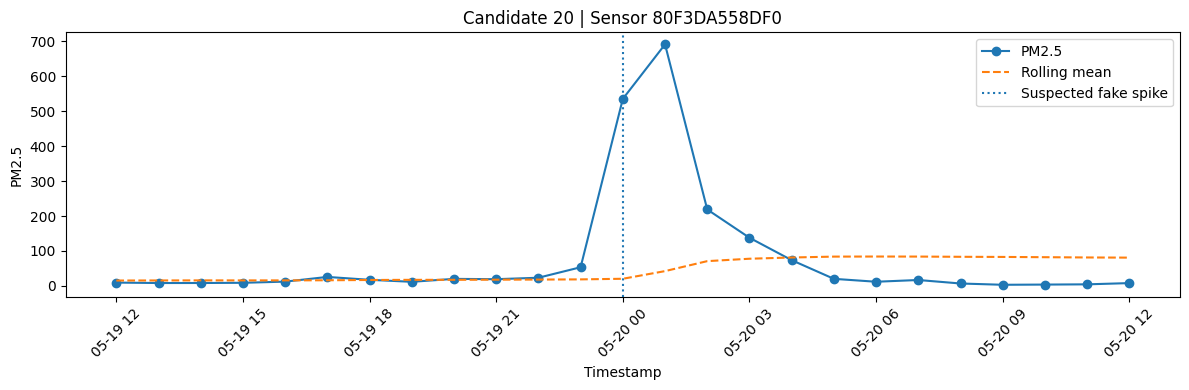

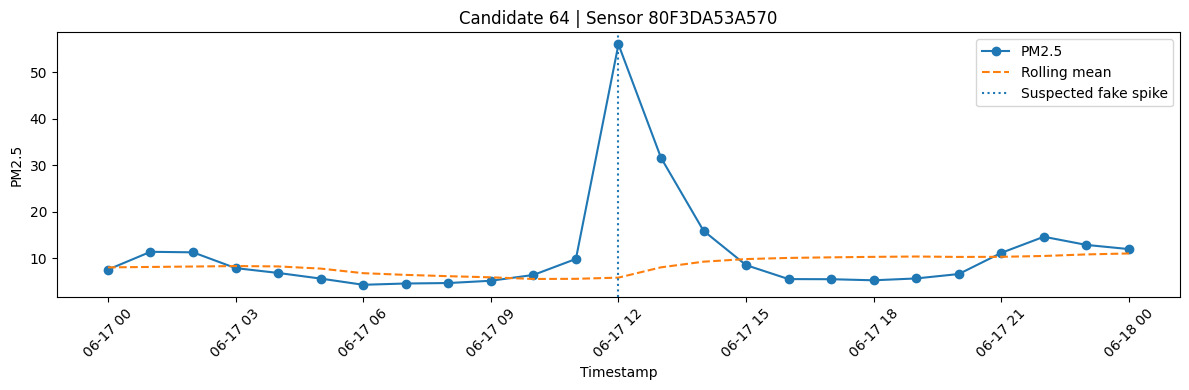

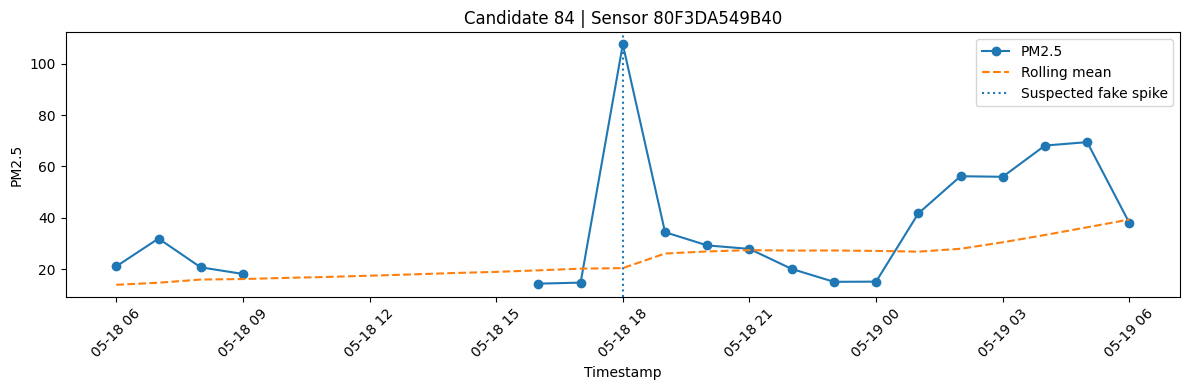

In [56]:
for candidate_id in real_spikes["candidate_id"].head(3):
    plot_real_spike_window(candidate_id)

In [60]:
# --------------------------------------------------
# Add other hourly sensor measurements to labelled spike candidates
# --------------------------------------------------

additional_columns = [
    "temperature",
    "humidity",
    "pm1p0",
    "pm10p0",
    "pm4p0",
    "voc",
    "nox",
    "co2"
]

# Keep only columns that actually exist in df_full
additional_columns = [
    col for col in additional_columns
    if col in df_full.columns
]

# Copy required columns from raw/full 5-minute dataframe
df_full_extra = df_full[["sensor_id", "timestamp"] + additional_columns].copy()

# Clean sensor IDs
df_full_extra["sensor_id"] = (
    df_full_extra["sensor_id"]
    .astype(str)
    .str.strip()
    .str.upper()
)

labelled_spike_candidates["sensor_id"] = (
    labelled_spike_candidates["sensor_id"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Convert timestamps to datetime
df_full_extra["timestamp"] = pd.to_datetime(df_full_extra["timestamp"], errors="coerce")
labelled_spike_candidates["timestamp"] = pd.to_datetime(
    labelled_spike_candidates["timestamp"],
    errors="coerce"
)

# Remove rows with invalid timestamps
df_full_extra = df_full_extra.dropna(subset=["timestamp"]).copy()
labelled_spike_candidates = labelled_spike_candidates.dropna(subset=["timestamp"]).copy()

# Convert both datasets to hourly timestamps
df_full_extra["timestamp"] = df_full_extra["timestamp"].dt.floor("h")
labelled_spike_candidates["timestamp"] = labelled_spike_candidates["timestamp"].dt.floor("h")

# Make sure extra columns are numeric
for col in additional_columns:
    df_full_extra[col] = pd.to_numeric(df_full_extra[col], errors="coerce")

# Aggregate 5-minute measurements to hourly level
df_full_hourly_extra = (
    df_full_extra
    .groupby(["sensor_id", "timestamp"], as_index=False)
    [additional_columns]
    .mean()
)

# Avoid duplicate columns if this cell is rerun
labelled_spike_candidates = labelled_spike_candidates.drop(
    columns=[col for col in additional_columns if col in labelled_spike_candidates.columns],
    errors="ignore"
)

# Merge hourly extra measurements into labelled spike candidates
labelled_spike_candidates = labelled_spike_candidates.merge(
    df_full_hourly_extra,
    on=["sensor_id", "timestamp"],
    how="left"
)

# Check missing values after merge
print("Extra columns added:")
print(additional_columns)

print("\nMissing percentage after merge:")
print(
    (labelled_spike_candidates[additional_columns].isna().mean() * 100)
    .sort_values(ascending=False)
)

print("\nMissing count after merge:")
print(labelled_spike_candidates[additional_columns].isna().sum())

Extra columns added:
['temperature', 'humidity', 'pm1p0', 'pm10p0', 'pm4p0', 'voc', 'nox', 'co2']

Missing percentage after merge:
temperature    0.0
humidity       0.0
pm1p0          0.0
pm10p0         0.0
pm4p0          0.0
voc            0.0
nox            0.0
co2            0.0
dtype: float64

Missing count after merge:
temperature    0
humidity       0
pm1p0          0
pm10p0         0
pm4p0          0
voc            0
nox            0
co2            0
dtype: int64


In [62]:
# save labelled_spike_candidates to CSV
labelled_spike_candidates.to_csv("labelled_spike_candidates.csv", index=False)